# FCA-PAD v4: realistic anomaly mix and monetary benefit
Runs **after** the v2 notebook (`FCA_PAD_v2_complete`) for the same log, and after nothing else.
It reuses v2's saved models, split, rules and calibration (no training) and writes only to
`<log folder>/18_v4_realistic/`. v2 and v3 files are not modified.

**How to run:** set `LOG_NAME` in cell 0.3 (same values as v2), then Runtime → Run all.
Repeat for each log. The last section collects every log that has been run.
CPU runtime is fine; each log takes roughly 5–15 minutes (three new worlds are generated and scored).

**Part A** is the v2 core (loading, audit constants, features, frozen models, rules, injection
helpers), copied unchanged except that it never rewrites v2 files.
**Part B** builds the new anomaly mix, **Part C** reports this log, **Part D** compares logs.


## Part A · v2 core (loads saved artefacts; trains nothing)


In [ ]:
# 0.1 Environment detection + package install
import importlib.util, os, subprocess, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
for pkg in ("pm4py", "pyarrow"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
# PuLP 4.0 (Oct 2026) removed names pm4py imports at start-up (LpStatus) -> pin PuLP < 4.
from importlib.metadata import version as _ver, PackageNotFoundError
try:
    _pulp_major = int(_ver("pulp").split(".")[0])
except PackageNotFoundError:
    _pulp_major = None
if _pulp_major is None or _pulp_major >= 4:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pulp<4"], check=True)
    if "pulp" in sys.modules or "pm4py" in sys.modules:
        raise SystemExit("PuLP was downgraded. Restart the session (Runtime > Restart session), then run again.")
print("Running in Colab:", IN_COLAB)


Running in Colab: True


In [ ]:
# 0.2 Safe Google Drive mount
# Removes /content/drive ONLY when it is a leftover local folder, never when
# it is the mounted Drive (deleting a mounted Drive deletes your real files).
if IN_COLAB:
    import shutil
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        if os.path.exists("/content/drive"):
            shutil.rmtree("/content/drive")
        drive.mount("/content/drive")
    else:
        print("Drive already mounted.")


Mounted at /content/drive


In [ ]:
# 0.3 CONFIGURATION — the only cell you should need to edit
import json, datetime, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ---- where everything lives (NEW folder; v1 folders untouched) ----------
LOG_NAME = os.environ.get("FCA_LOG", "BPIC20_D")   # BPIC20_D | BPIC20_I | BPIC20_PR | BPIC20_R

LOGS = {   # benchmark name -> file in github.com/guanwei49/BPAD/generator/real-life_Logs, amount field
    "BPIC20_D":  {"xes": "BPIC20_DomesticDeclarations.xes",      "amount": "case:Amount",
                  "local_xes": "DomesticDeclarations.xes", "multi_batch_hrs": 180},
    "BPIC20_I":  {"xes": "BPIC20_InternationalDeclarations.xes", "amount": "case:Amount"},
    "BPIC20_PR": {"xes": "BPIC20_PrepaidTravelCost.xes",         "amount": "case:RequestedAmount"},
    "BPIC20_R":  {"xes": "BPIC20_RequestForPayment.xes",         "amount": "case:RequestedAmount"},
}
assert LOG_NAME in LOGS, f"LOG_NAME must be one of {list(LOGS)}"
LOG_CFG = LOGS[LOG_NAME]
BASE_ROOT = ("/content/drive/MyDrive/FCA_PAD_v2" if IN_COLAB else os.path.abspath("FCA_PAD_v2"))
BASE_ROOT = os.environ.get("FCA_ROOT", BASE_ROOT)
ROOT = BASE_ROOT if LOG_NAME == "BPIC20_D" else f"{BASE_ROOT}/{LOG_NAME}"
XES_FILE = LOG_CFG.get("local_xes", LOG_CFG["xes"])
XES_URL = ("https://raw.githubusercontent.com/guanwei49/BPAD/master/generator/real-life_Logs/"
           + LOG_CFG["xes"])

# ---- dataset mapping (shared by all BPIC20 logs) --------------------------
CASE_COL, ACTIVITY_COL, TIME_COL = "case:concept:name", "concept:name", "time:timestamp"
ROLE_COL, RESOURCE_COL = "org:role", "org:resource"
AMOUNT_COL = LOG_CFG["amount"]
ACT_REQUEST = "Request Payment"
ACT_PAYMENT = "Payment Handled"
SUBMIT_TOKEN = "SUBMITTED by EMPLOYEE"   # any submission activity (declaration, permit, request)
REJECT_TOKEN = "REJECTED"                # any rejection activity
APPROVE_TOKEN = "APPROVED"               # any approval activity (incl. FINAL_APPROVED)

# ---- data-derived constants (None = derive from the log) ----------------
BATCH_WEEKDAYS = None   # BPIC20_D derives to [0, 3] = Monday, Thursday
BATCH_HOUR = None       # BPIC20_D derives to 15
MULTI_BATCH_HRS = LOG_CFG.get("multi_batch_hrs")   # D: 180 (v1 value); others: derived
REPEAT_WINDOW_D = 7     # cross-case amount proximity window (days)
RARE_AMOUNT_MAX = 3     # amount in <= N cases = rare
HEAVY_REWORK_LOOPS = 2

# ---- experiment settings ----------------------------------------------
RANDOM_SEED = 42
SPLIT = (0.60, 0.20, 0.20)              # train / val / test, by case
BUCKET_EDGES = (3, 5)                   # prefix buckets 1-3 | 4-5 | 6+
MIN_PREFIXES_PER_BUCKET = 2000
INJ_RATE = 0.05
INJ_TYPES = ["A1", "A2", "A4", "A5"]    # A3 omitted (no adjusted-amount field)
ALERT_FPR = 0.01                        # early-warning threshold on natural val prefixes
BOOTSTRAP_B = 200                       # bootstrap resamples for fusion selection
SEEDS_ROBUSTNESS = [42, 7, 123]
RUN_SEED_ROBUSTNESS = True
RUN_REGIME2 = True
NE_MAXLEN = 32                          # natural max 24; injection adds <= 2
AE_MAXLEN = 32
NE_EPOCHS, AE_EPOCHS = 60, 30
FORCE_RECOMPUTE = False   # True: ignore cached stage outputs
FORCE_REFREEZE = False    # True: overwrite FROZEN artefacts — leave False
if os.environ.get("FCA_SKIP_ROBUSTNESS"):   # skip section 10 (seeds + Regime 2) to save time
    RUN_SEED_ROBUSTNESS = RUN_REGIME2 = False
if os.environ.get("FCA_FAST"):          # quick code-path test only; never for results
    NE_EPOCHS = AE_EPOCHS = 2
    RUN_SEED_ROBUSTNESS = RUN_REGIME2 = False

# ---- folders -------------------------------------------------------------
RAW_DIR, PROCESSED_DIR = f"{ROOT}/01_raw", f"{ROOT}/02_processed"
FEATURE_DIR, MODEL_DIR = f"{ROOT}/03_features", f"{ROOT}/04_models"
RESULT_DIR, FIGURE_DIR = f"{ROOT}/05_results", f"{ROOT}/06_figures"
FROZEN_DIR = f"{ROOT}/00_frozen"
for d in [RAW_DIR, PROCESSED_DIR, FEATURE_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR, FROZEN_DIR]:
    os.makedirs(d, exist_ok=True)

np.random.seed(RANDOM_SEED)

def cached(path):
    return os.path.exists(path) and not FORCE_RECOMPUTE

def write_frozen(path, writer):
    """Write a frozen artefact once. Returns True if written now."""
    if os.path.exists(path) and not FORCE_REFREEZE:
        print(f"FROZEN (kept existing): {os.path.basename(path)}")
        return False
    writer(path)
    print(f"FROZEN (written now):  {os.path.basename(path)}")
    return True

E1, E2 = BUCKET_EDGES
BUCKETS = [f"1-{E1}", f"{E1+1}-{E2}", f"{E2+1}+"]
def bucket_of(k):
    return BUCKETS[0] if k <= E1 else (BUCKETS[1] if k <= E2 else BUCKETS[2])

def midpoint_rank(values, ref):
    """Percentile of values within sorted ref; ties get the tie-block midpoint."""
    ref = np.asarray(ref)
    if len(ref) == 0:
        return np.zeros(len(values))
    lo = np.searchsorted(ref, values, side="left")
    hi = np.searchsorted(ref, values, side="right")
    return np.clip((lo + hi) / 2 / len(ref), 0, 1)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGURE_DIR}/{name}.png", dpi=130)
    plt.show()
    plt.close()

env = {"python": sys.version.split()[0], "platform": platform.platform(),
       "pandas": pd.__version__, "numpy": np.__version__,
       "run_started": datetime.datetime.now().isoformat(timespec="seconds"),
       "root": ROOT, "log": LOG_NAME}
json.dump(env, open(f"{RESULT_DIR}/00_environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))


{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "run_started": "2026-10-13T04:28:05",
  "root": "/content/drive/MyDrive/FCA_PAD_v2",
  "log": "BPIC20_D"
}


In [ ]:
# A.0 v4 guard: side outputs of the v2 core go to a scratch folder; nothing may be trained
V2_RESULT_DIR = RESULT_DIR
V4_DIR = f"{ROOT}/18_v4_realistic"
RESULT_DIR, FIGURE_DIR = f"{V4_DIR}/_v2_core_outputs", f"{V4_DIR}/_v2_core_figures"
for d in (RESULT_DIR, FIGURE_DIR):
    os.makedirs(d, exist_ok=True)
FORCE_RECOMPUTE = FORCE_REFREEZE = False
_needed = [f"{PROCESSED_DIR}/events_sorted.parquet", f"{FEATURE_DIR}/prefix_features.parquet",
           f"{FEATURE_DIR}/natural_scores.parquet", f"{MODEL_DIR}/next_event.keras", f"{MODEL_DIR}/ae.keras",
           f"{MODEL_DIR}/if.joblib", f"{MODEL_DIR}/calibration_refs.joblib", f"{MODEL_DIR}/ne_meta.joblib",
           f"{FROZEN_DIR}/case_split.csv", f"{FROZEN_DIR}/rule_registry_v1.json",
           f"{FROZEN_DIR}/ground_truth_sealed.csv", f"{V2_RESULT_DIR}/07_fusion_selected.json"]
_missing = [p for p in _needed if not os.path.exists(p)]
if _missing:
    raise SystemExit("Run the v2 notebook for " + LOG_NAME + " first. Missing:\n  " + "\n  ".join(_missing))
print("v2 artefacts found for", LOG_NAME, "| v4 outputs ->", V4_DIR)


v2 artefacts found for BPIC20_D | v4 outputs -> /content/drive/MyDrive/FCA_PAD_v2/18_v4_realistic


In [ ]:
# 1.1 Load XES (or cached parquet), schema audit, quality checks, freeze
EVENTS_PATH = f"{PROCESSED_DIR}/events_sorted.parquet"
if cached(EVENTS_PATH):
    events = pd.read_parquet(EVENTS_PATH)
    print("Loaded cached events:", events.shape)
else:
    import pm4py
    xes_path = f"{RAW_DIR}/{XES_FILE}"
    if not os.path.exists(xes_path):
        import urllib.request, time as _t
        print(f"{XES_FILE} not in {RAW_DIR} - downloading from the benchmark repository ...")
        tmp = xes_path + ".part"
        for attempt in range(1, 4):              # download to .part, verify, then move into place
            try:
                with urllib.request.urlopen(XES_URL, timeout=120) as r:
                    expected = int(r.headers.get("Content-Length", 0))
                    with open(tmp, "wb") as fh:
                        while True:
                            chunk = r.read(1 << 20)
                            if not chunk:
                                break
                            fh.write(chunk)
                got = os.path.getsize(tmp)
                if expected and got != expected:
                    raise IOError(f"incomplete download: {got} of {expected} bytes")
                os.replace(tmp, xes_path)
                break
            except Exception as e:
                if os.path.exists(tmp):
                    os.remove(tmp)
                print(f"  attempt {attempt} failed: {e}")
                if attempt == 3:
                    raise RuntimeError(f"Download failed - upload {LOG_CFG['xes']} into {RAW_DIR} "
                                       f"and re-run this cell.") from e
                _t.sleep(5 * attempt)
        print("Downloaded", round(os.path.getsize(xes_path) / 1e6, 1), "MB")
    raw_df = pm4py.convert_to_dataframe(pm4py.read_xes(xes_path)).copy()
    print("Raw dataframe:", raw_df.shape)

    schema = pd.DataFrame([{
        "column": c, "dtype": str(raw_df[c].dtype),
        "n_unique": int(raw_df[c].nunique(dropna=True)),
        "missing_pct": round(float(raw_df[c].isna().mean() * 100), 3),
        "example": str(raw_df[c].dropna().iloc[0]) if raw_df[c].notna().any() else ""}
        for c in raw_df.columns])
    schema.to_csv(f"{RESULT_DIR}/01_raw_schema.csv", index=False)
    print(schema.to_string(index=False))

    raw_df[TIME_COL] = pd.to_datetime(raw_df[TIME_COL], utc=True, errors="coerce")
    if AMOUNT_COL in raw_df:
        raw_df[AMOUNT_COL] = pd.to_numeric(raw_df[AMOUNT_COL], errors="coerce")
    quality = {
        "missing_case_id": int(raw_df[CASE_COL].isna().sum()),
        "missing_activity": int(raw_df[ACTIVITY_COL].isna().sum()),
        "missing_or_bad_timestamp": int(raw_df[TIME_COL].isna().sum()),
        "exact_duplicate_rows": int(raw_df.astype(str).duplicated().sum()),
        "missing_amount": int(raw_df[AMOUNT_COL].isna().sum()) if AMOUNT_COL in raw_df else None,
    }
    print("Quality:", quality)
    # Rule: never delete records for looking unusual — only structurally invalid ones.
    bad = raw_df[CASE_COL].isna() | raw_df[ACTIVITY_COL].isna() | raw_df[TIME_COL].isna()
    print("Structurally invalid rows removed:", int(bad.sum()))
    raw_df = raw_df[~bad].copy()

    keep = {CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, RESOURCE_COL, AMOUNT_COL}
    const_cols = [c for c in raw_df.columns
                  if c not in keep and raw_df[c].nunique(dropna=False) <= 1]
    print("Constant columns dropped:", const_cols)
    raw_df = raw_df.drop(columns=const_cols)

    raw_df[CASE_COL] = raw_df[CASE_COL].astype(str)
    raw_df["_orig_order"] = np.arange(len(raw_df))
    events = (raw_df.sort_values([CASE_COL, TIME_COL, "_orig_order"])
              .drop(columns="_orig_order").reset_index(drop=True))
    events["event_idx"] = events.groupby(CASE_COL).cumcount() + 1
    for c in events.columns:                      # parquet-safe object columns
        if events[c].dtype == object:
            events[c] = events[c].where(events[c].isna(), events[c].astype(str))
    events.to_parquet(EVENTS_PATH, index=False)
    json.dump(quality, open(f"{RESULT_DIR}/01_quality.json", "w"), indent=2)
    print("Frozen:", events.shape, "->", EVENTS_PATH)

events[TIME_COL] = pd.to_datetime(events[TIME_COL], utc=True)
events[CASE_COL] = events[CASE_COL].astype(str)
for c in [CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, AMOUNT_COL]:
    assert c in events.columns, f"Required column missing: {c}"

tl = events.groupby(CASE_COL).size()
phase1 = {"cases": int(events[CASE_COL].nunique()), "events": len(events),
          "activities": int(events[ACTIVITY_COL].nunique()),
          "start": str(events[TIME_COL].min()), "end": str(events[TIME_COL].max()),
          "trace_len_min": int(tl.min()), "trace_len_median": float(tl.median()),
          "trace_len_max": int(tl.max())}
print(json.dumps(phase1, indent=2))
print(events[ACTIVITY_COL].value_counts().to_string())
pd.DataFrame([phase1]).to_csv(f"{RESULT_DIR}/01_phase1_summary.csv", index=False)


Loaded cached events: (56437, 10)
{
  "cases": 10500,
  "events": 56437,
  "activities": 17,
  "start": "2017-01-09 09:49:50+00:00",
  "end": "2019-06-17 17:30:58+00:00",
  "trace_len_min": 1,
  "trace_len_median": 5.0,
  "trace_len_max": 24
}
concept:name
Declaration SUBMITTED by EMPLOYEE             11531
Declaration FINAL_APPROVED by SUPERVISOR      10131
Payment Handled                               10044
Request Payment                               10040
Declaration APPROVED by ADMINISTRATION         8202
Declaration APPROVED by BUDGET OWNER           2820
Declaration REJECTED by EMPLOYEE               1365
Declaration REJECTED by ADMINISTRATION          952
Declaration APPROVED by PRE_APPROVER            685
Declaration REJECTED by SUPERVISOR              293
Declaration SAVED by EMPLOYEE                   135
Declaration REJECTED by MISSING                  91
Declaration REJECTED by PRE_APPROVER             86
Declaration REJECTED by BUDGET OWNER             59
Declaration FOR

In [ ]:
# 2.1 Variants
traces = events.groupby(CASE_COL)[ACTIVITY_COL].agg(list)
variant = traces.map(lambda t: " -> ".join(t))
variant_counts = variant.value_counts().rename_axis("variant").reset_index(name="cases")
variant_counts["share_%"] = (variant_counts["cases"] / len(traces) * 100).round(2)
variant_counts["cumulative_%"] = variant_counts["share_%"].cumsum().round(2)
variant_counts.to_csv(f"{RESULT_DIR}/02_variants.csv", index=False)
print("Distinct variants:", len(variant_counts),
      "| top-5 coverage:", variant_counts["cumulative_%"].iloc[min(4, len(variant_counts) - 1)], "%")
print(variant_counts.head(8).to_string(index=False))


Distinct variants: 99 | top-5 coverage: 89.56 %
                                                                                                                                                                                                                                                                                                                 variant  cases  share_%  cumulative_%
                                                                                                                                                           Declaration SUBMITTED by EMPLOYEE -> Declaration APPROVED by ADMINISTRATION -> Declaration FINAL_APPROVED by SUPERVISOR -> Request Payment -> Payment Handled   4618    43.98         43.98
                                                                                                                   Declaration SUBMITTED by EMPLOYEE -> Declaration APPROVED by ADMINISTRATION -> Declaration APPROVED by BUDGET OWNER -> Declaration FINAL_APPROVED by SU

In [ ]:
# 2.2 Rework structure (loop counter = resubmissions, not rejections // 2)
is_rej = events[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)
is_sub = events[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False)
is_app = events[ACTIVITY_COL].str.contains(APPROVE_TOKEN, regex=False)
per_case = pd.DataFrame({
    "n_rejections": is_rej.groupby(events[CASE_COL]).sum(),
    "n_submissions": is_sub.groupby(events[CASE_COL]).sum(),
    "n_approvals": is_app.groupby(events[CASE_COL]).sum()})
# a rework loop = a RE-submission of the same object (declaration / permit / request):
# per submission activity, every occurrence after the first counts as one loop.
_resub = (is_sub & (events.groupby([CASE_COL, ACTIVITY_COL]).cumcount() >= 1))
per_case["n_rework_loops"] = _resub.groupby(events[CASE_COL]).sum()
print("Cases with >=1 rejection :", int((per_case.n_rejections > 0).sum()))
print("Cases with rework loops  :", int((per_case.n_rework_loops > 0).sum()))
print("Rejection-count distribution:",
      per_case.n_rejections.value_counts().sort_index().head(10).to_dict())

ev_seq = events[[CASE_COL, ACTIVITY_COL, TIME_COL, "event_idx"]].copy()
ev_seq["next_act"] = ev_seq.groupby(CASE_COL)[ACTIVITY_COL].shift(-1)
ev_seq["next_time"] = ev_seq.groupby(CASE_COL)[TIME_COL].shift(-1)
ev_seq["gap_h"] = (ev_seq["next_time"] - ev_seq[TIME_COL]).dt.total_seconds() / 3600
follow = (ev_seq[ev_seq[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)]
          .groupby([ACTIVITY_COL, "next_act"]).size().rename("n").reset_index()
          .sort_values([ACTIVITY_COL, "n"], ascending=[True, False]))
print("\nTop followers of each rejection type:")
print(follow.groupby(ACTIVITY_COL).head(2).to_string(index=False))
follow.to_csv(f"{RESULT_DIR}/02_rejection_followers.csv", index=False)


Cases with >=1 rejection : 1301
Cases with rework loops  : 1019
Rejection-count distribution: {0: 9199, 1: 86, 2: 1058, 3: 16, 4: 128, 5: 1, 6: 10, 7: 1, 12: 1}

Top followers of each rejection type:
                          concept:name                          next_act    n
Declaration REJECTED by ADMINISTRATION  Declaration REJECTED by EMPLOYEE  928
Declaration REJECTED by ADMINISTRATION Declaration SUBMITTED by EMPLOYEE   19
  Declaration REJECTED by BUDGET OWNER  Declaration REJECTED by EMPLOYEE   58
  Declaration REJECTED by BUDGET OWNER Declaration SUBMITTED by EMPLOYEE    1
      Declaration REJECTED by EMPLOYEE Declaration SUBMITTED by EMPLOYEE 1081
       Declaration REJECTED by MISSING Declaration SUBMITTED by EMPLOYEE   61
  Declaration REJECTED by PRE_APPROVER  Declaration REJECTED by EMPLOYEE   85
  Declaration REJECTED by PRE_APPROVER Declaration SUBMITTED by EMPLOYEE    1
    Declaration REJECTED by SUPERVISOR  Declaration REJECTED by EMPLOYEE  286
    Declaration REJE

In [ ]:
# 2.3 Transition timing
transitions = (ev_seq.dropna(subset=["next_act"])
               .groupby([ACTIVITY_COL, "next_act"])["gap_h"]
               .agg(count="count", median_h="median", mean_h="mean", max_h="max")
               .sort_values("count", ascending=False).round(2).reset_index())
transitions.to_csv(f"{RESULT_DIR}/03_transitions.csv", index=False)
print(transitions.head(10).to_string(index=False))
req_pay_gaps = ev_seq[(ev_seq[ACTIVITY_COL] == ACT_REQUEST) &
                      (ev_seq["next_act"] == ACT_PAYMENT)]["gap_h"].dropna()
print("\nRequest -> Payment gap percentiles (h):")
print(req_pay_gaps.quantile([.05, .25, .5, .75, .9, .95, .99]).round(1).to_string())


                            concept:name                                 next_act  count  median_h  mean_h    max_h
Declaration FINAL_APPROVED by SUPERVISOR                          Request Payment  10038     27.43   75.91  5631.32
                         Request Payment                          Payment Handled  10037     77.77   85.79  1491.48
       Declaration SUBMITTED by EMPLOYEE   Declaration APPROVED by ADMINISTRATION   8202      0.01   27.74  6781.98
  Declaration APPROVED by ADMINISTRATION Declaration FINAL_APPROVED by SUPERVISOR   5133     20.88   45.65  1198.17
  Declaration APPROVED by ADMINISTRATION     Declaration APPROVED by BUDGET OWNER   2820     20.77   45.55  1198.31
    Declaration APPROVED by BUDGET OWNER Declaration FINAL_APPROVED by SUPERVISOR   2788     45.83   68.74   284.46
       Declaration SUBMITTED by EMPLOYEE Declaration FINAL_APPROVED by SUPERVISOR   1536      0.01   22.76  3458.33
        Declaration REJECTED by EMPLOYEE        Declaration SUBMITTED by

Payment share by weekday: {'Mon': 0.4275, 'Tue': 0.0026, 'Wed': 0.0001, 'Thu': 0.5698, 'Fri': 0.0, 'Sat': 0.0, 'Sun': 0.0}
BATCH_WEEKDAYS=['Mon', 'Thu']  BATCH_HOUR=17  batch share=0.9973  BATCHED=True  MULTI_BATCH_HRS=180


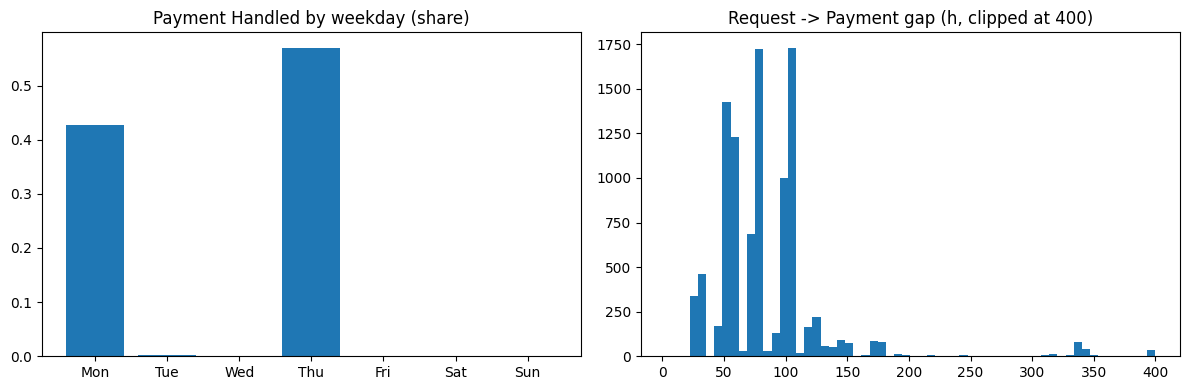

In [ ]:
# 2.4 Payment batch schedule — DERIVED from the data
pay_ev = events[events[ACTIVITY_COL] == ACT_PAYMENT].copy()
dow_share = (pay_ev[TIME_COL].dt.weekday.value_counts(normalize=True)
             .reindex(range(7), fill_value=0.0))
if BATCH_WEEKDAYS is None:
    BATCH_WEEKDAYS = sorted(int(d) for d in dow_share[dow_share >= 0.10].index)
batch_share = float(dow_share[BATCH_WEEKDAYS].sum()) if BATCH_WEEKDAYS else 0.0
BATCHED = bool(batch_share >= 0.90 and 0 < len(BATCH_WEEKDAYS) <= 3)
if BATCH_HOUR is None:
    on_batch = pay_ev[pay_ev[TIME_COL].dt.weekday.isin(BATCH_WEEKDAYS)]
    BATCH_HOUR = int(on_batch[TIME_COL].dt.hour.mode().iloc[0]) if len(on_batch) else 12
if MULTI_BATCH_HRS is None:
    if BATCHED and len(BATCH_WEEKDAYS) > 1:
        d = BATCH_WEEKDAYS + [BATCH_WEEKDAYS[0] + 7]
        MULTI_BATCH_HRS = 2 * 24 * max(np.diff(d))
    elif BATCHED:
        MULTI_BATCH_HRS = 2 * 24 * 7
    else:
        MULTI_BATCH_HRS = float(req_pay_gaps.quantile(0.95))
DAYNAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Payment share by weekday:",
      {DAYNAMES[i]: round(float(v), 4) for i, v in dow_share.items()})
print(f"BATCH_WEEKDAYS={[DAYNAMES[d] for d in BATCH_WEEKDAYS]}  BATCH_HOUR={BATCH_HOUR}  "
      f"batch share={batch_share:.4f}  BATCHED={BATCHED}  MULTI_BATCH_HRS={MULTI_BATCH_HRS}")

def hours_to_next_batch_vec(ts):
    """Hours from each timestamp to the next scheduled batch slot (UTC).
    Returns zeros when the log has no batch schedule."""
    ts = pd.to_datetime(pd.Series(ts), utc=True)
    if not BATCHED:
        return pd.Series(0.0, index=ts.index)
    base = ts.dt.normalize() + pd.Timedelta(hours=BATCH_HOUR)
    best = pd.Series(pd.NaT, index=ts.index, dtype="datetime64[ns, UTC]")
    for add in range(8):
        cand = base + pd.Timedelta(days=add)
        ok = cand.dt.weekday.isin(BATCH_WEEKDAYS) & (cand > ts) & best.isna()
        best.loc[ok] = cand.loc[ok]
    return (best - ts).dt.total_seconds() / 3600

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(DAYNAMES, dow_share.values)
ax[0].set_title("Payment Handled by weekday (share)")
ax[1].hist(req_pay_gaps.clip(upper=400), bins=60)
ax[1].set_title("Request -> Payment gap (h, clipped at 400)")
save_fig("02_payment_batching")

derived = {"BATCH_WEEKDAYS": BATCH_WEEKDAYS, "BATCH_HOUR": BATCH_HOUR,
           "BATCHED": BATCHED, "batch_share": batch_share,
           "MULTI_BATCH_HRS": float(MULTI_BATCH_HRS),
           "median_req_to_pay_h": float(req_pay_gaps.median()) if len(req_pay_gaps) else None}
json.dump(derived, open(f"{RESULT_DIR}/02_derived_constants.json", "w"), indent=2)


In [ ]:
# 2.5 Prefix-length structure + bucket density (prefix space)
cases_reaching_k = events.groupby("event_idx")[CASE_COL].nunique()
prefix_table = pd.DataFrame({"k": cases_reaching_k.index,
                             "cases_reaching_k": cases_reaching_k.values})
prefix_table["share_%"] = (prefix_table["cases_reaching_k"] / phase1["cases"] * 100).round(1)
prefix_table.to_csv(f"{RESULT_DIR}/02_prefix_lengths.csv", index=False)
print(prefix_table.head(12).to_string(index=False))
bucket_density = events["event_idx"].map(bucket_of).value_counts().reindex(BUCKETS)
print("\nPrefixes per bucket:", bucket_density.to_dict())
for b, n in bucket_density.items():
    if n < MIN_PREFIXES_PER_BUCKET:
        print(f"WARNING: bucket {b} has {n} prefixes (< {MIN_PREFIXES_PER_BUCKET}); "
              f"consider changing BUCKET_EDGES.")


 k  cases_reaching_k  share_%
 1             10500    100.0
 2             10366     98.7
 3             10361     98.7
 4             10135     96.5
 5              8691     82.8
 6              3490     33.2
 7               997      9.5
 8               918      8.7
 9               505      4.8
10               207      2.0
11               122      1.2
12                69      0.7

Prefixes per bucket: {'1-3': 31227, '4-5': 18826, '6+': 6384}


In [ ]:
# 2.6 Case skeleton
grp = events.groupby(CASE_COL)
skel = grp.agg(start_time=(TIME_COL, "min"), end_time=(TIME_COL, "max"),
               length=("event_idx", "max"), amount=(AMOUNT_COL, "first"))
skel["duration_h"] = ((skel.end_time - skel.start_time).dt.total_seconds() / 3600).round(2)
skel["variant"] = variant
skel["n_request_payment"] = (events[ACTIVITY_COL] == ACT_REQUEST).groupby(events[CASE_COL]).sum()
skel["n_payment_handled"] = (events[ACTIVITY_COL] == ACT_PAYMENT).groupby(events[CASE_COL]).sum()
skel = skel.join(per_case)
skel["has_missing_role"] = (events[ROLE_COL] == "MISSING").groupby(events[CASE_COL]).any()
skel["reaches_payment"] = skel["n_payment_handled"] > 0
skel = skel.reset_index()
pass  # v4: v2 file not rewritten
print("Case skeleton:", skel.shape)


Case skeleton: (10500, 15)


In [ ]:
# 2.7 Payment structure: duplicates, bypasses, off-batch, never-paid, delays
max_pay = int(skel.n_payment_handled.max())
max_req = int(skel.n_request_payment.max())
pay_no_req = skel[(skel.n_payment_handled > 0) & (skel.n_request_payment == 0)]
req_no_pay = skel[(skel.n_request_payment > 0) & (skel.n_payment_handled == 0)]
if BATCHED:
    off_ids = set(pay_ev.loc[~pay_ev[TIME_COL].dt.weekday.isin(BATCH_WEEKDAYS), CASE_COL])
else:
    off_ids = set()
off_batch = skel[skel[CASE_COL].isin(off_ids)]
never_paid = skel[~skel.reaches_payment]
gap_case = (ev_seq[(ev_seq[ACTIVITY_COL] == ACT_REQUEST) & (ev_seq["next_act"] == ACT_PAYMENT)]
            .set_index(CASE_COL)["gap_h"])
delayed = skel[skel[CASE_COL].isin(gap_case[gap_case > MULTI_BATCH_HRS].index)]
heavy_rework = skel[skel.n_rework_loops >= HEAVY_REWORK_LOOPS]

print(f"Max Payment Handled per case: {max_pay} | max Request Payment per case: {max_req}")
print("Payment WITHOUT request (natural bypass):", len(pay_no_req))
print("Request WITHOUT payment                 :", len(req_no_pay))
print("Off-batch payment cases                 :", len(off_batch))
print(f"Never-paid cases: {len(never_paid)} "
      f"(rejected-terminal {int((never_paid.n_rejections > 0).sum())}, "
      f"abandoned {int((never_paid.n_rejections == 0).sum())})")
print(f"Multi-batch delayed (> {MULTI_BATCH_HRS} h)    :", len(delayed))
print(f"Heavy rework (>= {HEAVY_REWORK_LOOPS} loops)          :", len(heavy_rework))
for name, df_ in [("pay_without_request", pay_no_req), ("request_without_pay", req_no_pay),
                  ("off_batch_payments", off_batch), ("never_paid", never_paid),
                  ("multi_batch_delayed", delayed), ("heavy_rework", heavy_rework)]:
    df_.to_csv(f"{RESULT_DIR}/02_{name}.csv", index=False)


Max Payment Handled per case: 1 | max Request Payment per case: 1
Payment WITHOUT request (natural bypass): 7
Request WITHOUT payment                 : 3
Off-batch payment cases                 : 27
Never-paid cases: 456 (rejected-terminal 322, abandoned 134)
Multi-batch delayed (> 180 h)    : 230
Heavy rework (>= 2 loops)          : 126


In [ ]:
# 2.8 Cross-case rare-amount clusters (rarity filter + cluster chaining + payment time)
pay_time = pay_ev.groupby(CASE_COL)[TIME_COL].first().rename("pay_time")
amt2 = (skel.set_index(CASE_COL)[["amount"]].join(pay_time, how="inner")
        .reset_index().dropna())
amount_freq_all = skel["amount"].value_counts()
amt2["is_rare"] = amt2["amount"].map(amount_freq_all).le(RARE_AMOUNT_MAX)
amt2 = amt2.sort_values(["amount", "pay_time"])
amt2["gap_d"] = amt2.groupby("amount")["pay_time"].diff().dt.total_seconds() / 86400
amt2["cluster_id"] = (amt2["gap_d"].isna() | (amt2["gap_d"] > REPEAT_WINDOW_D)).cumsum()
clusters = amt2.groupby("cluster_id").agg(
    amount=("amount", "first"), n_cases=(CASE_COL, "nunique"), rare=("is_rare", "first"),
    first_pay=("pay_time", "min"), last_pay=("pay_time", "max"))
clusters["same_instant"] = clusters["first_pay"] == clusters["last_pay"]
rare_clusters = clusters[(clusters.n_cases >= 2) & clusters.rare]
member = amt2.merge(rare_clusters[[]], left_on="cluster_id", right_index=True)
RARE_CLUSTER_CASES = set(member[CASE_COL])
print("Multi-case clusters within window:", int((clusters.n_cases >= 2).sum()))
print("Rare-amount clusters:", len(rare_clusters), "| cases:", len(RARE_CLUSTER_CASES),
      "| same-instant:", int(rare_clusters.same_instant.sum()))
rare_clusters.to_csv(f"{RESULT_DIR}/02_rare_amount_clusters.csv")
pd.Series(sorted(RARE_CLUSTER_CASES), name=CASE_COL).to_csv(
    f"{RESULT_DIR}/02_rare_cluster_cases.csv", index=False)


Multi-case clusters within window: 285
Rare-amount clusters: 123 | cases: 253 | same-instant: 105


In [ ]:
# 2.9 Track-B PRE-REGISTRATION (frozen before any model exists)
TRACKB = {
    "C1_payment_without_request": set(pay_no_req[CASE_COL]),
    "C2_off_batch_payment": set(off_batch[CASE_COL]),
    "C3_rare_amount_cluster": RARE_CLUSTER_CASES,
    "C4_multi_batch_delay": set(delayed[CASE_COL]),
    "C5_heavy_rework": set(heavy_rework[CASE_COL]),
}
def _write_prereg(path):
    lines = [f"# Track-B pre-registration — {LOG_NAME}",
             f"Frozen: {datetime.datetime.now().isoformat(timespec='seconds')}",
             "Written BEFORE any detector was trained. Criteria and thresholds:",
             f"- C1 payment without request (n={len(TRACKB['C1_payment_without_request'])})",
             f"- C2 payment outside batch weekdays {[DAYNAMES[d] for d in BATCH_WEEKDAYS]} "
             f"(n={len(TRACKB['C2_off_batch_payment'])})",
             f"- C3 rare amount (in <= {RARE_AMOUNT_MAX} cases) repeated across cases paid "
             f"within {REPEAT_WINDOW_D} days (n={len(RARE_CLUSTER_CASES)})",
             f"- C4 request->payment gap > {MULTI_BATCH_HRS} h (n={len(TRACKB['C4_multi_batch_delay'])})",
             f"- C5 >= {HEAVY_REWORK_LOOPS} rework loops (n={len(TRACKB['C5_heavy_rework'])})",
             "Verdict rule: 'domain-supported suspicious' = >= 2 independent indicators "
             "from different perspectives; 1 indicator = weak support.",
             "Overlap disclosure: C1, C2, C3, C4 and C5 also exist as F-rules (F6, F7, F3, F8, F9); "
             "plausibility is reported with and without overlap cases."]
    open(path, "w").write("\n".join(lines))
write_frozen(f"{FROZEN_DIR}/trackB_preregistration.md", _write_prereg)
print(open(f"{FROZEN_DIR}/trackB_preregistration.md").read())

audit = {"max_pay_per_case": max_pay, "pay_without_request": len(pay_no_req),
         "request_without_pay": len(req_no_pay), "off_batch_cases": len(off_batch),
         "never_paid": len(never_paid), "rare_clusters": len(rare_clusters),
         "rare_cluster_cases": len(RARE_CLUSTER_CASES), "delayed": len(delayed),
         "heavy_rework": len(heavy_rework), "variants": len(variant_counts), **derived}
pd.DataFrame([audit]).to_csv(f"{RESULT_DIR}/02_audit_summary.csv", index=False)


FROZEN (kept existing): trackB_preregistration.md
# Track-B pre-registration — BPIC20_D
Frozen: 2026-10-03T08:16:09
Written BEFORE any detector was trained. Criteria and thresholds:
- C1 payment without request (n=7)
- C2 payment outside batch weekdays [] (n=0)
- C3 rare amount (in <= 3 cases) repeated across cases paid within 7 days (n=253)
- C4 request->payment gap > 180 h (n=230)
- C5 >= 2 rework loops (n=126)
Verdict rule: 'domain-supported suspicious' = >= 2 independent indicators from different perspectives; 1 indicator = weak support.
Overlap disclosure: C1, C2, C3, C4 and C5 also exist as F-rules (F6, F7, F3, F8, F9); plausibility is reported with and without overlap cases.


In [ ]:
# 3.1 Train / val / test split by case (FROZEN)
from sklearn.model_selection import train_test_split
SPLIT_PATH = f"{FROZEN_DIR}/case_split.csv"
def _write_split(path):
    ids, strat = skel[CASE_COL], skel["reaches_payment"]
    tr, tmp = train_test_split(ids, test_size=1 - SPLIT[0],
                               random_state=RANDOM_SEED, stratify=strat)
    va, te = train_test_split(tmp, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
                              random_state=RANDOM_SEED, stratify=strat.loc[tmp.index])
    out = pd.DataFrame({CASE_COL: ids, "split": "train"})
    out.loc[out[CASE_COL].isin(va), "split"] = "val"
    out.loc[out[CASE_COL].isin(te), "split"] = "test"
    out.to_csv(path, index=False)
write_frozen(SPLIT_PATH, _write_split)
split_map = pd.read_csv(SPLIT_PATH, dtype={CASE_COL: str}).set_index(CASE_COL)["split"]
events["split"] = events[CASE_COL].map(split_map)
skel["split"] = skel[CASE_COL].map(split_map)
assert events["split"].notna().all(), "cases missing from the frozen split"
print(skel["split"].value_counts().to_dict())
print("reaches_payment share:", skel.groupby("split")["reaches_payment"].mean().round(4).to_dict())


FROZEN (kept existing): case_split.csv
{'train': 6300, 'val': 2100, 'test': 2100}
reaches_payment share: {'test': 0.9567, 'train': 0.9565, 'val': 0.9567}


In [ ]:
# 3.2 Feature builder — ONE function for the natural and the injected world.
# SET B (behavioural) + SET S (state): no money. SET F: money, consequence lane only.
def build_features(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True).copy()
    ev[TIME_COL] = pd.to_datetime(ev[TIME_COL], utc=True)
    ev["prefix_key"] = (ev.groupby(CASE_COL)[ACTIVITY_COL]
                        .transform(lambda s: (s + "|").cumsum().str[:-1]))
    ev["prev_act"] = ev.groupby(CASE_COL)[ACTIVITY_COL].shift(1)
    tr = ev["split"] == "train"                     # train-only statistic maps
    pf_map = ev.loc[tr, "prefix_key"].value_counts()
    tf_map = ev[tr & ev["prev_act"].notna()].groupby(["prev_act", ACTIVITY_COL]).size()
    rare_cut = tf_map.sum() * 0.001
    tr_amt = ev[tr].groupby(CASE_COL)[AMOUNT_COL].first().dropna()
    amt_freq, amt_sorted = tr_amt.value_counts(), np.sort(tr_amt.values)

    p = ev[[CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, "event_idx", "split",
            "prefix_key", "prev_act"]].copy()
    g = p.groupby(CASE_COL)
    p["B_len"] = p["event_idx"]
    p["B_n_unique_acts"] = g[ACTIVITY_COL].transform(lambda s: (~s.duplicated()).cumsum())
    p["B_unique_ratio"] = p["B_n_unique_acts"] / p["B_len"]
    p["B_repeat_ratio"] = 1 - p["B_unique_ratio"]
    p["_s"] = p[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False).astype(int)
    p["_r"] = p[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False).astype(int)
    p["_a"] = p[ACTIVITY_COL].str.contains(APPROVE_TOKEN, regex=False).astype(int)
    p["_rs_"] = ((p["_s"] == 1) & (p.groupby([CASE_COL, ACTIVITY_COL]).cumcount() >= 1)).astype(int)
    p["B_n_submissions_so_far"] = g["_s"].cumsum()
    p["B_n_rejections_so_far"] = g["_r"].cumsum()
    p["B_n_approvals_so_far"] = g["_a"].cumsum()
    p["B_rework_loops_so_far"] = p.groupby(CASE_COL)["_rs_"].cumsum()
    pf = p["prefix_key"].map(pf_map).fillna(0.0)
    p["B_prefix_log_freq"] = np.log1p(pf)
    p["B_prefix_is_unseen"] = (pf == 0).astype(int)
    tf_ = pd.Series(tf_map.reindex(pd.MultiIndex.from_frame(p[["prev_act", ACTIVITY_COL]])).values,
                    index=p.index).fillna(0.0)
    p["_rt"] = ((tf_ < rare_cut) & p["prev_act"].notna()).astype(int)
    p["B_rare_trans_so_far"] = g["_rt"].cumsum()
    p["_rc"] = p[ROLE_COL].replace({"MISSING": "UNKNOWN_ROLE"})
    p["_rs"] = ((p["_rc"] != g["_rc"].shift(1)) & g["_rc"].shift(1).notna()).astype(int)
    p["B_role_switches_so_far"] = g["_rs"].cumsum()
    p["_mr"] = (p[ROLE_COL] == "MISSING").astype(int)
    p["B_missing_role_so_far"] = g["_mr"].cumsum().clip(upper=1)
    p["_gap"] = (p[TIME_COL] - g[TIME_COL].shift(1)).dt.total_seconds() / 3600
    p["B_dur_so_far_h"] = (p[TIME_COL] - g[TIME_COL].transform("first")).dt.total_seconds() / 3600
    p["B_mean_gap_h"] = p["B_dur_so_far_h"] / (p["B_len"] - 1).clip(lower=1)
    p["B_max_gap_h"] = p.groupby(CASE_COL)["_gap"].cummax().fillna(0.0)
    p["B_last_gap_h"] = p["_gap"].fillna(0.0)
    p["_we"] = (p[TIME_COL].dt.weekday >= 5).astype(int)
    p["_oh"] = (~p[TIME_COL].dt.hour.between(8, 18)).astype(int)
    p["B_weekend_ratio_so_far"] = g["_we"].cumsum() / p["B_len"]
    p["B_offhours_ratio_so_far"] = g["_oh"].cumsum() / p["B_len"]
    p["_ir"] = (p[ACTIVITY_COL] == ACT_REQUEST).astype(int)
    p["_ip"] = (p[ACTIVITY_COL] == ACT_PAYMENT).astype(int)
    p["S_n_requests_so_far"] = g["_ir"].cumsum()
    p["S_n_payments_so_far"] = g["_ip"].cumsum()
    p["S_request_seen"] = (p["S_n_requests_so_far"] > 0).astype(int)
    p["S_payment_seen"] = (p["S_n_payments_so_far"] > 0).astype(int)
    p["_rtf"] = p[TIME_COL].where(p["_ir"] == 1).groupby(p[CASE_COL]).ffill()
    p["S_hours_since_request"] = ((p[TIME_COL] - p["_rtf"]).dt.total_seconds() / 3600
                                  ).fillna(0.0).clip(lower=0)
    p["_bw"] = np.nan
    m = p["_ir"] == 1
    if m.any():
        p.loc[m, "_bw"] = hours_to_next_batch_vec(p.loc[m, TIME_COL]).values
    p["_bw"] = p.groupby(CASE_COL)["_bw"].ffill()
    p["B_excess_wait_h"] = (p["S_hours_since_request"] - p["_bw"]).clip(lower=0).fillna(0.0)
    p["B_multi_batch_delay"] = (p["S_hours_since_request"] > MULTI_BATCH_HRS).astype(int)
    p["S_hours_to_next_batch"] = hours_to_next_batch_vec(p[TIME_COL]).values
    # ---- SET F (consequence lane only) ----
    amt_map = ev.groupby(CASE_COL)[AMOUNT_COL].first()
    p["F_amount"] = p[CASE_COL].map(amt_map)
    p["F_log_amount"] = np.log1p(p["F_amount"].clip(lower=0))
    p["F_amount_train_freq"] = p["F_amount"].map(amt_freq).fillna(0)
    p["F_is_rare_amount"] = (p["F_amount_train_freq"] <= RARE_AMOUNT_MAX).astype(int)
    p["F_amount_pctile"] = (np.searchsorted(amt_sorted, p["F_amount"].fillna(0).values)
                            / max(len(amt_sorted), 1))
    p["F_potential_exposure"] = np.where((p["S_request_seen"] == 1) & (p["S_payment_seen"] == 0),
                                         p["F_amount"].fillna(0), 0.0)
    p["F_settled_amount"] = np.where(p["S_payment_seen"] == 1, p["F_amount"].fillna(0), 0.0)
    p["bucket"] = p["event_idx"].map(bucket_of)
    return p.drop(columns=[c for c in p.columns if c.startswith("_")] + ["prefix_key", "prev_act"])

PX_PATH = f"{FEATURE_DIR}/prefix_features.parquet"
if cached(PX_PATH):
    px = pd.read_parquet(PX_PATH)
    px[TIME_COL] = pd.to_datetime(px[TIME_COL], utc=True)
    print("Loaded cached prefix features:", px.shape)
else:
    px = build_features(events)
    px.to_parquet(PX_PATH, index=False)
    print("Built prefix features:", px.shape)

B_COLS = [c for c in px.columns if c.startswith("B_")]
S_COLS = [c for c in px.columns if c.startswith("S_")]
F_COLS = [c for c in px.columns if c.startswith("F_")]
DETECTOR_FEATURES = B_COLS + S_COLS
leaky = [c for c in DETECTOR_FEATURES if "amount" in c.lower() or c.startswith("F_")]
assert not leaky, f"SEAL VIOLATION: {leaky}"
assert len(px) == len(events), "one row per event (= per prefix) expected"
assert px[DETECTOR_FEATURES + F_COLS].isna().sum().sum() == 0, "NaNs in features"
pd.DataFrame({"feature": B_COLS + S_COLS + F_COLS,
              "set": ["B"] * len(B_COLS) + ["S"] * len(S_COLS) + ["F"] * len(F_COLS),
              "detector_input": [True] * len(DETECTOR_FEATURES) + [False] * len(F_COLS)}
             )  # v4: v2 file not rewritten
print(f"Detector features: {len(DETECTOR_FEATURES)} | financial features: {len(F_COLS)} | seal OK")
print("Unseen-prefix share by split:", px.groupby("split")["B_prefix_is_unseen"].mean().round(4).to_dict())


Loaded cached prefix features: (56437, 41)
Detector features: 27 | financial features: 7 | seal OK
Unseen-prefix share by split: {'test': 0.0029, 'train': 0.0, 'val': 0.002}


In [ ]:
# 4.1 TensorFlow setup
import joblib
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
tf.keras.utils.set_random_seed(RANDOM_SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
train_mask = (px["split"] == "train").values


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 4.2 BASELINE 1 — Isolation Forest on tabular B+S features
IF_PATH, SCALER_PATH = f"{MODEL_DIR}/if.joblib", f"{MODEL_DIR}/scaler.joblib"
if cached(IF_PATH) and cached(SCALER_PATH):
    if_model, scaler = joblib.load(IF_PATH), joblib.load(SCALER_PATH)
    print("Loaded Isolation Forest.")
else:
    scaler = StandardScaler().fit(px.loc[train_mask, DETECTOR_FEATURES])
    if_model = IsolationForest(n_estimators=200, max_samples=256, random_state=RANDOM_SEED,
                               n_jobs=-1).fit(scaler.transform(px.loc[train_mask, DETECTOR_FEATURES]))
    joblib.dump(if_model, IF_PATH); joblib.dump(scaler, SCALER_PATH)
    print("Trained Isolation Forest.")

def score_if(p):
    return -if_model.score_samples(scaler.transform(p[DETECTOR_FEATURES]))


Loaded Isolation Forest.


In [ ]:
# 4.3 BASELINE 2 — LSTM autoencoder on activity sequences (v1 design, mean error)
AE_PATH, AE_META = f"{MODEL_DIR}/ae.keras", f"{MODEL_DIR}/ae_meta.joblib"
if cached(AE_META):
    ae_meta = joblib.load(AE_META)
else:
    acts = sorted(events.loc[events.split == "train", ACTIVITY_COL].unique())
    ae_meta = {"act2id": {a: i + 1 for i, a in enumerate(acts)}}
    ae_meta["UNK"] = len(acts) + 1
    ae_meta["VOCAB"] = len(acts) + 2
    joblib.dump(ae_meta, AE_META)
ACT2ID, AE_UNK, AE_VOCAB = ae_meta["act2id"], ae_meta["UNK"], ae_meta["VOCAB"]

def prefix_seq_matrix(ev, p):
    seqs = (ev.sort_values([CASE_COL, "event_idx"]).groupby(CASE_COL)[ACTIVITY_COL]
            .agg(lambda s: [ACT2ID.get(a, AE_UNK) for a in s]).to_dict())
    M = np.zeros((len(p), AE_MAXLEN), dtype=np.int32)
    for i, (cid, k) in enumerate(zip(p[CASE_COL].values, p["event_idx"].values)):
        ids = seqs[cid][:min(int(k), AE_MAXLEN)]
        M[i, :len(ids)] = ids
    return M

def build_ae():
    inp = layers.Input(shape=(AE_MAXLEN,), dtype="int32")
    h = layers.Embedding(AE_VOCAB, 16, mask_zero=True)(inp)
    h = layers.LSTM(64)(h)
    h = layers.RepeatVector(AE_MAXLEN)(h)
    h = layers.LSTM(64, return_sequences=True)(h)
    out = layers.TimeDistributed(layers.Dense(AE_VOCAB, activation="softmax"))(h)
    m = Model(inp, out)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    return m

def score_ae(model, M, batch=4096):
    errs = np.zeros(len(M))
    for s in range(0, len(M), batch):
        xb = M[s:s + batch]
        probs = model.predict(xb, verbose=0)
        pt = np.take_along_axis(probs, xb[..., None], axis=2)[..., 0]
        ce = -np.log(np.clip(pt, 1e-9, 1.0))
        mk = xb > 0
        errs[s:s + batch] = (ce * mk).sum(1) / np.maximum(mk.sum(1), 1)
    return errs

SEQ_NAT = prefix_seq_matrix(events, px)
if cached(AE_PATH):
    ae = tf.keras.models.load_model(AE_PATH, compile=False)
    print("Loaded autoencoder.")
else:
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    ae = build_ae()
    ae.fit(SEQ_NAT[train_mask], SEQ_NAT[train_mask], validation_split=0.1,
           epochs=AE_EPOCHS, batch_size=256, verbose=2,
           callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    ae.save(AE_PATH)


Loaded autoencoder.


In [ ]:
# 4.4 IMPROVED — multi-perspective next-event model
# Event score = -log P(activity, role, time-gap bucket | earlier events); prefix
# score = max over its events (worst event, not diluted). Causal => one pass
# scores every prefix, so it is streaming-native. No amount enters the model.
GAP_EDGES_H = [1 / 60, 1, 24, 72, 168]
PAD, BOS, UNK, EOS = 0, 1, 2, 3     # EOS teaches the model where a case ends
NE_VARIANTS = {"act": ["act"], "act_role": ["act", "role"], "full": ["act", "role", "gap"]}
NE_SCORE_COLS = [f"{agg}_{v}" for agg in ["max", "mean"] for v in NE_VARIANTS]

def add_tokens(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).copy()
    gap_h = ev.groupby(CASE_COL)[TIME_COL].diff().dt.total_seconds() / 3600
    b = np.digitize(gap_h.fillna(0).values, GAP_EDGES_H) + 1
    ev["gap_tok"] = np.where(gap_h.isna().values, 0, b).astype(str)
    ev["role_tok"] = ev[ROLE_COL].fillna("NA").astype(str).replace({"MISSING": "UNKNOWN_ROLE"})
    return ev

NE_COLS = {"act": ACTIVITY_COL, "role": "role_tok", "gap": "gap_tok"}
PERSP = list(NE_COLS)
NE_META = f"{MODEL_DIR}/ne_meta.joblib"
ev_tok = add_tokens(events)
if cached(NE_META):
    VOC = joblib.load(NE_META)["VOC"]
else:
    trm = ev_tok["split"] == "train"
    VOC = {p: {v: i + 4 for i, v in enumerate(sorted(ev_tok.loc[trm, c].unique()))}
           for p, c in NE_COLS.items()}
    joblib.dump({"VOC": VOC, "GAP_EDGES_H": GAP_EDGES_H, "NE_MAXLEN": NE_MAXLEN}, NE_META)
VSIZE = {p: len(v) + 4 for p, v in VOC.items()}
print("Next-event vocab sizes:", VSIZE)

def encode_cases(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).copy()
    for p in PERSP:
        ev[f"_{p}"] = ev[NE_COLS[p]].map(VOC[p]).fillna(UNK).astype(np.int32)
    groups = list(ev.groupby(CASE_COL, sort=True))
    n = len(groups)
    Y = {p: np.zeros((n, NE_MAXLEN), np.int32) for p in PERSP}
    lens, ids = np.zeros(n, np.int32), []
    for i, (cid, gdf) in enumerate(groups):
        ids.append(cid)
        lens[i] = len(gdf)
        L = min(len(gdf), NE_MAXLEN - 1)          # leave room for EOS
        for p in PERSP:
            Y[p][i, :L] = gdf[f"_{p}"].values[:L]
            if len(gdf) <= NE_MAXLEN - 1:
                Y[p][i, L] = EOS                   # target after the last event
    X = {p: np.concatenate([np.full((n, 1), BOS, np.int32), Y[p][:, :-1]], 1) for p in PERSP}
    return np.array(ids), X, Y, lens

def masked_sce(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    m = tf.cast(y_true > 0, ce.dtype)
    return tf.reduce_sum(ce * m) / tf.maximum(tf.reduce_sum(m), 1.0)

def build_ne(hidden=128, drop=0.1):
    dims = {"act": 32, "role": 8, "gap": 8}
    ins = [layers.Input((NE_MAXLEN,), dtype="int32", name=f"in_{p}") for p in PERSP]
    embs = [layers.Embedding(VSIZE[p], dims[p])(i) for p, i in zip(PERSP, ins)]
    h = layers.Dropout(drop)(layers.Concatenate()(embs))
    h = layers.LSTM(hidden, return_sequences=True)(h)
    h = layers.Dropout(drop)(h)
    h = layers.LSTM(hidden, return_sequences=True)(h)
    outs = [layers.Dense(VSIZE[p], activation="softmax", name=f"out_{p}")(h) for p in PERSP]
    m = Model(ins, outs)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=[masked_sce] * len(PERSP))
    return m

def train_ne(ev_tokens_train, seed, verbose=2):
    tf.keras.utils.set_random_seed(seed)
    _, X, Y, _ = encode_cases(ev_tokens_train)
    idx = np.random.default_rng(seed).permutation(len(Y["act"]))
    cut = int(0.9 * len(idx))
    a, b = idx[:cut], idx[cut:]
    m = build_ne()
    m.fit([X[p][a] for p in PERSP], [Y[p][a] for p in PERSP],
          validation_data=([X[p][b] for p in PERSP], [Y[p][b] for p in PERSP]),
          epochs=NE_EPOCHS, batch_size=128, verbose=verbose,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return m

def ne_event_scores(model, ev_tokens):
    """Per-event NLL per perspective + prefix scores (max/mean x variants)."""
    cids, X, Y, lens = encode_cases(ev_tokens)
    probs = model.predict([X[p] for p in PERSP], batch_size=512, verbose=0)
    mask = np.arange(NE_MAXLEN)[None, :] < np.minimum(lens, NE_MAXLEN - 1)[:, None]  # real events only
    ci, ti = np.nonzero(mask)
    d = pd.DataFrame({CASE_COL: cids[ci], "event_idx": ti + 1})
    for p, pr in zip(PERSP, probs):
        pt = np.take_along_axis(pr, Y[p][..., None], axis=2)[..., 0]
        d[f"nll_{p}"] = -np.log(np.clip(pt[ci, ti], 1e-9, 1.0))
    for v, parts in NE_VARIANTS.items():
        e = d[[f"nll_{p}" for p in parts]].sum(axis=1)
        d[f"e_{v}"] = e
        d[f"max_{v}"] = e.groupby(d[CASE_COL]).cummax()
        d[f"mean_{v}"] = e.groupby(d[CASE_COL]).cumsum() / d["event_idx"]
    return d

NE_PATH = f"{MODEL_DIR}/next_event.keras"
if cached(NE_PATH):
    ne_model = tf.keras.models.load_model(NE_PATH, compile=False)
    print("Loaded next-event model.")
else:
    ne_model = train_ne(ev_tok[ev_tok.split == "train"], RANDOM_SEED)
    ne_model.save(NE_PATH)


Next-event vocab sizes: {'act': 20, 'role': 11, 'gap': 11}
Loaded next-event model.


In [ ]:
# 4.5 Score the natural log with every detector; per-bucket calibration on TRAIN
RAW_TO_A = {"raw_IF": "A_IF", "raw_AE": "A_AE",
            **{c: f"A_NE_{c}" for c in NE_SCORE_COLS}}

def score_detectors(ev, p, model=None, seq=None):
    """Adds raw detector scores to prefix table p (rows aligned by case, event_idx)."""
    model = model or ne_model
    out = p.copy()
    out["raw_IF"] = score_if(out)
    out["raw_AE"] = score_ae(ae, seq if seq is not None else prefix_seq_matrix(ev, out))
    ne = ne_event_scores(model, add_tokens(ev))
    out = out.merge(ne[[CASE_COL, "event_idx"] + NE_SCORE_COLS],
                    on=[CASE_COL, "event_idx"], how="left")
    out[NE_SCORE_COLS] = out.groupby(CASE_COL)[NE_SCORE_COLS].ffill()   # beyond NE_MAXLEN
    return out, ne

def fit_refs(p, mask):
    return {f"{c}|{b}": np.sort(p.loc[mask & (p["bucket"] == b).values, c].values)
            for c in RAW_TO_A for b in BUCKETS}

def apply_refs(p, refs):
    for raw, a in RAW_TO_A.items():
        out = np.zeros(len(p))
        for b in BUCKETS:
            m = (p["bucket"] == b).values
            out[m] = midpoint_rank(p.loc[m, raw].values, refs[f"{raw}|{b}"])
        p[a] = out
    p["A_ENS"] = (p["A_IF"] + p["A_AE"]) / 2           # v1 anomaly lane
    return p

NAT_SCORES = f"{FEATURE_DIR}/natural_scores.parquet"
NAT_NE_EV = f"{FEATURE_DIR}/natural_ne_events.parquet"
REFS_PATH = f"{MODEL_DIR}/calibration_refs.joblib"
if cached(NAT_SCORES) and cached(NAT_NE_EV) and cached(REFS_PATH):
    px = pd.read_parquet(NAT_SCORES)
    px[TIME_COL] = pd.to_datetime(px[TIME_COL], utc=True)
    ne_nat = pd.read_parquet(NAT_NE_EV)
    REFS = joblib.load(REFS_PATH)
    print("Loaded cached natural scores.")
else:
    px, ne_nat = score_detectors(events, px, seq=SEQ_NAT)
    REFS = fit_refs(px, train_mask)
    px = apply_refs(px, REFS)
    joblib.dump(REFS, REFS_PATH)
    ne_nat.to_parquet(NAT_NE_EV, index=False)
    px.to_parquet(NAT_SCORES, index=False)
A_NE_COLS = [f"A_NE_{c}" for c in NE_SCORE_COLS]
A_ALL = ["A_IF", "A_AE", "A_ENS"] + A_NE_COLS
print("Calibrated means by split (train = 0.50 by construction):")
print(px.groupby("split")[A_ALL].mean().round(3).T.to_string())
print("\nCorrelations: IF~AE %.3f | AE~NE(max_full) %.3f" % (
    px["A_IF"].corr(px["A_AE"]), px["A_AE"].corr(px["A_NE_max_full"])))


Loaded cached natural scores.
Calibrated means by split (train = 0.50 by construction):
split                test  train    val
A_IF                0.489    0.5  0.497
A_AE                0.494    0.5  0.501
A_ENS               0.492    0.5  0.499
A_NE_max_act        0.495    0.5  0.501
A_NE_max_act_role   0.494    0.5  0.499
A_NE_max_full       0.496    0.5  0.499
A_NE_mean_act       0.495    0.5  0.502
A_NE_mean_act_role  0.495    0.5  0.500
A_NE_mean_full      0.496    0.5  0.502

Correlations: IF~AE 0.540 | AE~NE(max_full) 0.496


In [ ]:
# 5.1 Rule registry v1 (FROZEN before fusion tuning and Track-B review)
REG_PATH = f"{FROZEN_DIR}/rule_registry_v1.json"
def _write_registry(path):
    reg = {"version": "1.0", "log": LOG_NAME,
           "frozen": datetime.datetime.now().isoformat(timespec="seconds"),
           "thresholds": {"batched": BATCHED, "batch_weekdays": BATCH_WEEKDAYS,
                          "batch_hour": BATCH_HOUR, "multi_batch_hrs": float(MULTI_BATCH_HRS),
                          "repeat_window_d": REPEAT_WINDOW_D, "rare_amount_max": RARE_AMOUNT_MAX,
                          "heavy_rework_loops": HEAVY_REWORK_LOOPS},
           "rules": {
               "F1": {"name": "Duplicate payment in case", "consequence": "loss", "severity": 3,
                      "survey_type": "rework", "source": "audit practice"},
               "F2": {"name": "Repeated payment request", "consequence": "exposure", "severity": 3,
                      "survey_type": "insert", "source": "audit practice"},
               "F3": {"name": "Rare amount in cross-case payment cluster", "consequence": "exposure",
                      "severity": 2, "survey_type": "attribute", "source": "audit + data"},
               "F6": {"name": "Payment without request (bypass)", "consequence": "exposure",
                      "severity": 3, "survey_type": "skip", "source": "audit practice"},
               "F7": {"name": "Off-batch payment", "consequence": "exposure", "severity": 2,
                      "survey_type": "attribute", "source": "data-derived"},
               "F8": {"name": "Multi-batch payment delay", "consequence": "exposure", "severity": 1,
                      "survey_type": "late", "source": "data-derived"},
               "F9": {"name": "Heavy rework reaching payment", "consequence": "exposure",
                      "severity": 1, "survey_type": "rework", "source": "data-derived"},
               "F10": {"name": "New request after an existing payment", "consequence": "exposure",
                       "severity": 3, "survey_type": "insert", "source": "audit practice"}},
           "omitted": {"F4": "within-case amount repeat impossible (one amount per case); folded into F3",
                       "F5": "amount inflation: no adjusted-amount field; Track A only (A3 not injected)"}}
    json.dump(reg, open(path, "w"), indent=2)
write_frozen(REG_PATH, _write_registry)
REG = json.load(open(REG_PATH))
RULES = list(REG["rules"])
print("Registry frozen on", REG["frozen"], "| rules:", RULES)


FROZEN (kept existing): rule_registry_v1.json
Registry frozen on 2026-10-03T08:23:10 | rules: ['F1', 'F2', 'F3', 'F6', 'F7', 'F8', 'F9', 'F10']


In [ ]:
# 5.2 Rule engine (prefix-computable) + F calibration on natural TRAIN prefixes
def apply_rules(p):
    th = REG["thresholds"]
    is_req = p[ACTIVITY_COL] == ACT_REQUEST
    is_pay = p[ACTIVITY_COL] == ACT_PAYMENT
    h = pd.DataFrame(index=p.index)
    h["F1"] = p["S_n_payments_so_far"] >= 2
    h["F2"] = p["S_n_requests_so_far"] >= 2
    h["F3"] = p[CASE_COL].isin(RARE_CLUSTER_CASES) & (p["S_payment_seen"] == 1)
    h["F6"] = (p["S_payment_seen"] == 1) & (p["S_n_requests_so_far"] == 0)
    if th["batched"]:
        offb = (is_pay & ~p[TIME_COL].dt.weekday.isin(th["batch_weekdays"])).astype(int)
        h["F7"] = offb.groupby(p[CASE_COL]).cummax() > 0
    else:
        h["F7"] = False
    h["F8"] = p["S_hours_since_request"] > th["multi_batch_hrs"]
    h["F9"] = (p["B_rework_loops_so_far"] >= th["heavy_rework_loops"]) & (p["S_payment_seen"] == 1)
    rap = (is_req & (p["S_n_payments_so_far"] >= 1)).astype(int)
    h["F10"] = rap.groupby(p[CASE_COL]).cummax() > 0
    h = h[RULES].astype(int)
    sev = sum(h[r] * REG["rules"][r]["severity"] for r in RULES)
    loss_rules = [r for r in RULES if REG["rules"][r]["consequence"] == "loss"]
    amt = p["F_amount"].fillna(0).clip(lower=0).values
    actual = np.where(h[loss_rules].sum(axis=1).values > 0, amt, 0.0)
    expo = np.where((sev.values > 0) & (actual == 0), amt, 0.0)
    out = p.copy()
    for r in RULES:
        out[f"hit_{r}"] = h[r].values
    out["severity_sum"] = sev.values
    out["n_rules_fired"] = h.sum(axis=1).values
    out["actual_loss"], out["potential_exposure"] = actual, expo
    out["money_at_risk"] = actual + expo
    out["F_raw"] = np.log1p(out["money_at_risk"]) * out["severity_sum"]
    return out

def apply_F(p):
    p["F"] = 0.0
    pos = p["F_raw"] > 0
    p.loc[pos, "F"] = midpoint_rank(p.loc[pos, "F_raw"].values, F_REF)
    return p

px = apply_rules(px)
F_REF = np.sort(px.loc[train_mask & (px["F_raw"] > 0).values, "F_raw"].values)
pass  # v4: v2 file not rewritten
px = apply_F(px)
print("Natural rule firings (prefixes):", {r: int(px[f"hit_{r}"].sum()) for r in RULES})
print("Prefixes with >=1 rule:", int((px.n_rules_fired > 0).sum()),
      "| F train-ref size:", len(F_REF))
pass  # v4: v2 file not rewritten


Natural rule firings (prefixes): {'F1': 0, 'F2': 0, 'F3': 253, 'F6': 7, 'F7': 0, 'F8': 232, 'F9': 123, 'F10': 0}
Prefixes with >=1 rule: 602 | F train-ref size: 366


In [ ]:
# 6.1 Injection engine — dtype-safe, batch-conformant, deterministic
REQ_PAY_POOL = req_pay_gaps.values if len(req_pay_gaps) else np.array([72.0])
APPROVALS = [a for a in events[ACTIVITY_COL].unique() if APPROVE_TOKEN in a]

def _next_slot(after_ts, rng):
    if BATCHED:
        base = after_ts.normalize()
        for add in range(9):
            cand = base + pd.Timedelta(days=add, hours=BATCH_HOUR,
                                       minutes=int(rng.integers(0, 60)))
            if cand.weekday() in BATCH_WEEKDAYS and cand > after_ts:
                return cand
    return after_ts + pd.Timedelta(hours=float(rng.choice(REQ_PAY_POOL)))

def _inject_case(cdf, itype, rng):
    cdf = cdf.sort_values("event_idx").reset_index(drop=True)
    cdf["_inj"] = 0
    amt = float(cdf[AMOUNT_COL].iloc[0])
    pay_i = cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]
    req_i = cdf.index[cdf[ACTIVITY_COL] == ACT_REQUEST]
    gt = {"type": itype, "amount": amt, "loss": 0.0, "exposure": 0.0}
    if itype == "A1":                                    # duplicate payment
        new = cdf.loc[[pay_i[-1]]].copy()
        new[TIME_COL] = _next_slot(cdf.loc[pay_i[-1], TIME_COL], rng)
        new["_inj"] = 1
        cdf = pd.concat([cdf, new], ignore_index=True)
        gt["loss"] = amt
    elif itype in ("A2", "A4"):                          # duplicate request (+ payment)
        new_r = cdf.loc[[req_i[-1]]].copy()
        new_r[TIME_COL] = cdf.loc[pay_i[-1], TIME_COL] + pd.Timedelta(hours=float(rng.uniform(24, 120)))
        new_r["_inj"] = 1
        parts = [cdf, new_r]
        if itype == "A4":
            new_p = cdf.loc[[pay_i[-1]]].copy()
            new_p[TIME_COL] = _next_slot(new_r[TIME_COL].iloc[0], rng)
            new_p["_inj"] = 2
            parts.append(new_p)
            gt["loss"] = amt
        else:
            gt["exposure"] = amt
        cdf = pd.concat(parts, ignore_index=True)
    elif itype == "A5":                                  # approval bypass (skip)
        cdf = cdf[~cdf[ACTIVITY_COL].isin(APPROVALS)].reset_index(drop=True)
        gt["exposure"] = amt
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    cdf["event_idx"] = np.arange(1, len(cdf) + 1)
    if itype == "A1":
        a = l = int(cdf.index[cdf["_inj"] == 1][0])
    elif itype == "A2":
        a, l = int(cdf.index[cdf["_inj"] == 1][0]), None
    elif itype == "A4":
        a, l = int(cdf.index[cdf["_inj"] == 1][0]), int(cdf.index[cdf["_inj"] == 2][0])
    else:
        a = int(cdf.index[cdf[ACTIVITY_COL] == ACT_REQUEST][0])
        l = int(cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT][0])
    gt["anomaly_pos"] = a + 1
    gt["loss_pos"] = None if l is None else l + 1
    gt["anomaly_time"] = cdf.loc[a, TIME_COL]
    gt["loss_time"] = None if l is None else cdf.loc[l, TIME_COL]
    return cdf.drop(columns="_inj"), gt

def inject_world(ev, target_splits, rate, seed):
    rng = np.random.default_rng(seed)
    targets = {}
    for sp in target_splits:
        n_split = int((skel["split"] == sp).sum())
        pool = skel[(skel["split"] == sp) & skel["reaches_payment"] &
                    (skel["n_request_payment"] >= 1) & (skel["n_approvals"] >= 1) &
                    (skel["length"] >= 4)]
        chosen = pool.sample(n=min(int(round(rate * n_split)), len(pool)),
                             random_state=seed)[CASE_COL].tolist()
        rng.shuffle(chosen)
        for i, cid in enumerate(chosen):
            targets[cid] = INJ_TYPES[i % len(INJ_TYPES)]
    tgt = sorted(targets)
    by_case = {cid: g for cid, g in ev[ev[CASE_COL].isin(tgt)].groupby(CASE_COL)}
    mods, gts = [], []
    for cid in tgt:
        cdf, gt = _inject_case(by_case[cid].copy(), targets[cid], rng)
        gt[CASE_COL], gt["split"] = cid, split_map[cid]
        mods.append(cdf); gts.append(gt)
    out = pd.concat([ev[~ev[CASE_COL].isin(tgt)]] + mods, ignore_index=True)
    out = out.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    out[TIME_COL] = pd.to_datetime(out[TIME_COL], utc=True)
    out["event_idx"] = out["event_idx"].astype(int)
    out[AMOUNT_COL] = pd.to_numeric(out[AMOUNT_COL], errors="coerce")
    gt = pd.DataFrame(gts)
    gt["gt_money"] = gt["loss"] + gt["exposure"]
    return out, gt

INJ_SEED = RANDOM_SEED
events_inj, gt_new = inject_world(events, ["val", "test"], INJ_RATE, INJ_SEED)
GT_PATH = f"{FROZEN_DIR}/ground_truth_sealed.csv"
write_frozen(GT_PATH, lambda path: gt_new.to_csv(path, index=False))
gt = pd.read_csv(GT_PATH, dtype={CASE_COL: str})
same = (set(zip(gt[CASE_COL], gt["type"])) == set(zip(gt_new[CASE_COL], gt_new["type"])))
assert same, ("Regenerated injection differs from the frozen ground truth. Do not change "
              "INJ_RATE/RANDOM_SEED/INJ_TYPES after freezing, or set FORCE_REFREEZE=True.")
gt = gt_new                                       # identical; keeps typed timestamps
pass  # v4: v2 file not rewritten
print("Injected cases:", len(gt), gt["type"].value_counts().to_dict(),
      "| GT money:", round(gt["gt_money"].sum(), 2),
      "| events:", len(events), "->", len(events_inj))


FROZEN (kept existing): ground_truth_sealed.csv
Injected cases: 210 {'A1': 54, 'A4': 52, 'A2': 52, 'A5': 52} | GT money: 20804.54 | events: 56437 -> 56533


# Part B · v4: realistic anomaly mix and monetary benefit
Everything below is new. It builds fresh worlds (new random seeds, never seen before) in which
most anomalies are **harmless decoys** and a minority are **costly**, some of them invisible to a
process model. It then scores each world with the frozen v2 models, applies the v3 financial
layer, and measures money recovered and **net benefit in euros** under a review budget.

Costly types (money from the scenario, not from the rules):
- **A1** duplicate payment inside a case (v2 type, has a v1 rule: F1)
- **A5** approval bypass (v2 type, no v1 rule)
- **C1** duplicate claim filed as a new case (ACFE "multiple reimbursement")
- **C2** overstated amount, above the permit budget (ACFE "overstated expense"; logs with a budget field)
- **C3** threshold splitting to avoid director approval (logs with amount-based director routing)
- **C4** paid despite a final rejection (control failure)

Decoys (no money): **D1** rework storm, **D2** swapped approvals, **D3** long wait before
processing, **D4** repeated approval. They are what most real process deviations look like.

Rule sets: **registry v1** is frozen from v2 and has no rule for A5, C1–C4 (hold-out types).
**Registry v3** adds standard audit tests (F11–F15), defined below before any world is generated.


In [ ]:
# B.0 v4 configuration and pre-registration
import time
V4_SEEDS = [int(s) for s in os.environ.get("V4_SEEDS", "404,505,606").split(",")]   # 101 = development seed
COSTLY_RATE = 0.03            # share of val/test cases that receive a costly anomaly
DECOY_RATIO_MAX = 10          # decoys per costly anomaly in the generated world
RATIOS = [0, 1, 4, 10]        # decoy:costly ratios evaluated on TEST (by sub-sampling decoys)
K = 50                        # review budget
REVIEW_COSTS = [10, 25, 50, 100]   # euros per reviewed case, for net benefit
K_GRID = [10, 20, 30, 50, 75, 100, 150, 200]
B_SELECT, B_CI = 200, 1000
LAMBDAS = [0, 0.25, 0.5, 1, 2, 4, 8]
TRANSFORMS = ["log", "linear"]
PR_FLOOR = 0.02
OTHER_RULE_WEIGHT = 0.5
DUP_WINDOW_D, SPLIT_WINDOW_D = 60, 7
COSTLY_TYPES_ALL = ["A1", "A5", "C1", "C2", "C3", "C4"]
DECOY_TYPES = ["D1", "D2", "D3", "D4"]
os.makedirs(V4_DIR, exist_ok=True)

PREREG_V4 = f"""# FCA-PAD v4 pre-registration (realistic anomaly mix)
Written: {{written}}   Log: {LOG_NAME}

Worlds: new injection seeds {V4_SEEDS}, val/test only, training untouched.
Costly anomalies: {COSTLY_RATE:.0%} of val/test cases, equal share per available type
({', '.join(COSTLY_TYPES_ALL)}; C2 only with a budget field, C3 only with director routing).
Decoys: {DECOY_RATIO_MAX} per costly anomaly, equal share of {', '.join(DECOY_TYPES)}.
Money: A1, C1 = case amount paid twice (loss); C2 = inflated part (loss); C4 = amount paid
despite rejection (loss); A5, C3 = amount paid without the required approval (exposure).

Positives for detection metrics: costly anomalies only; decoys count as negatives.
Selection: on VAL of each world (all decoys), objective ⅓ PR-AUC + ⅔ Loss Recall@{K},
PR-AUC floor −{PR_FLOOR}; λ ∈ {LAMBDAS}; money scale ∈ {{{{log, linear}}}}.

Layers compared: v3 form  = P(anomaly) × money × (1 + λ·g)
                 v4 form  = P(costly | behaviour z, rule hits) × money × (1 + λ·g), where
                            P(costly | ·) is a logistic model fitted on VAL (rules act as evidence,
                            so a rule can surface an anomaly the process model cannot see).
Primary system: v4 form with the FROZEN registry v1.
Primary hypotheses (TEST, decoy ratio 10:1, mean over seeds, paired-bootstrap 95% CIs):
- H10 The primary system recovers more lost money in the top {K}
      than P(anomaly) alone and than the v2 fusion.
- H11 It does so on hold-out types with no v1 rule (A5, C1–C4).
- H12 Its benefit grows with the decoy ratio (0, 1, 4, 10).
- H13 Net benefit = lost money recovered in top {K} − review cost × {K} is higher than for
      P(anomaly) alone at every review cost in {REVIEW_COSTS} €/case.
Secondary: registry v3 audit tests (F11–F15) add further recovery; their firing rate on
natural TRAIN cases is reported as the false-alarm cost.
Registry v3 rules (author-defined from standard audit tests, fixed here):
- F11 payment requested or made with no approval recorded
- F12 same rare amount (≤ 3 TRAIN occurrences) and same organisation key in an earlier case
      within {DUP_WINDOW_D} days (duplicate claim)
- F13 two cases of the same organisation within {SPLIT_WINDOW_D} days, each below the director
      threshold T, together at or above T (threshold splitting)
- F14 paid or requested after a rejection with no approval since that rejection
- F15 amount / budget above the TRAIN 99th percentile of that ratio
"""
_pr = f"{FROZEN_DIR}/preregistration_v4.md"
if not os.path.exists(_pr) or os.path.getsize(_pr) == 0:
    _txt = PREREG_V4.format(written=datetime.datetime.now().isoformat(timespec="seconds"))
    with open(_pr, "w") as fh:
        fh.write(_txt)
    print("Pre-registration v4 written:", _pr)
else:
    print("Pre-registration v4 kept:", (open(_pr).read().split("\n") + ["", ""])[1])


Pre-registration v4 written: /content/drive/MyDrive/FCA_PAD_v2/00_frozen/preregistration_v4.md


In [ ]:
# B.1 Data-derived constants (natural TRAIN cases only)
FUS = json.load(open(f"{V2_RESULT_DIR}/07_fusion_selected.json"))
BEST_A = FUS["anomaly_lane"]; RAW_A = BEST_A.replace("A_NE_", "")
tr_ev = events[events["split"] == "train"]
tr_case = tr_ev.groupby(CASE_COL).first()
tr_paid = set(tr_ev.loc[tr_ev[ACTIVITY_COL] == ACT_PAYMENT, CASE_COL])
case_cols = set(events.columns)
BUDGET_COL = next((c for c in ["case:Permit RequestedBudget", "case:RequestedBudget"]
                   if c in case_cols and pd.to_numeric(events[c], errors="coerce").gt(0).mean() > 0.5), None)
ORG_COL = next((c for c in ["case:OrganizationalEntity", "case:Permit OrganizationalEntity"]
                if c in case_cols and events[c].nunique() > 1), None)
RATIO_Q99 = None
if BUDGET_COL:
    b = pd.to_numeric(tr_case.loc[tr_case.index.isin(tr_paid), BUDGET_COL], errors="coerce")
    a = tr_case.loc[tr_case.index.isin(tr_paid), AMOUNT_COL]
    r = (a / b)[(b > 0)].dropna()
    RATIO_Q99 = float(r.quantile(0.99))
DIR_TOKEN = "DIRECTOR"
dir_cases = set(tr_ev.loc[tr_ev[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False), CASE_COL])
# C3 only where director approval is amount-based: (almost) no director below the threshold
DIR_T, DIR_SHARE_BELOW = None, None
if len(dir_cases) >= 15:
    _t = float(tr_case.loc[tr_case.index.isin(dir_cases), AMOUNT_COL].quantile(0.05))
    _below = tr_case[tr_case[AMOUNT_COL] < _t]
    DIR_SHARE_BELOW = float(_below.index.isin(dir_cases).mean()) if len(_below) else 1.0
    DIR_T = _t if DIR_SHARE_BELOW <= 0.01 else None
amt_train_freq = tr_case[AMOUNT_COL].round(2).value_counts()
_rej = tr_ev[tr_ev[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)
             & ~tr_ev[ROLE_COL].isin(["EMPLOYEE", "MISSING", "UNDEFINED"])]
REJ_ACT = _rej[ACTIVITY_COL].value_counts().index[0]
REJ_ROLE = _rej.loc[_rej[ACTIVITY_COL] == REJ_ACT, ROLE_COL].mode().iloc[0]
SUB_ACT = tr_ev.loc[tr_ev[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False), ACTIVITY_COL].value_counts().index[0]
_req = tr_case.index[tr_case.index.isin(set(tr_ev.loc[tr_ev[ACTIVITY_COL] == ACT_REQUEST, CASE_COL]))]
PI_PAY = float(pd.Index(_req).isin(tr_paid).mean()) if len(_req) else 1.0
COSTLY_TYPES = [t for t in COSTLY_TYPES_ALL if not ((t == "C2" and BUDGET_COL is None) or
                                                     (t == "C3" and (DIR_T is None or ORG_COL is None)))]
DOC_COLS = [c for c in ["case:DeclarationNumber", "case:RfpNumber"] if c in case_cols]
V4_CONST = {"v2_lane": BEST_A, "budget_col": BUDGET_COL, "ratio_q99": RATIO_Q99, "org_col": ORG_COL,
            "director_threshold": DIR_T, "n_director_train_cases": len(dir_cases),
            "director_share_below_threshold": DIR_SHARE_BELOW, "pi_pay": PI_PAY,
            "rejection_activity": REJ_ACT, "rejection_role": REJ_ROLE, "submission_activity": SUB_ACT,
            "costly_types": COSTLY_TYPES}
json.dump(V4_CONST, open(f"{V4_DIR}/v4_constants.json", "w"), indent=2, default=str)
print(json.dumps(V4_CONST, indent=2, default=str))


{
  "v2_lane": "A_NE_max_act",
  "budget_col": null,
  "ratio_q99": null,
  "org_col": null,
  "director_threshold": null,
  "n_director_train_cases": 0,
  "director_share_below_threshold": null,
  "pi_pay": 0.9998340248962656,
  "rejection_activity": "Declaration REJECTED by ADMINISTRATION",
  "rejection_role": "ADMINISTRATION",
  "submission_activity": "Declaration SUBMITTED by EMPLOYEE",
  "costly_types": [
    "A1",
    "A5",
    "C1",
    "C4"
  ]
}


In [ ]:
# B.2 Injectors. Each returns a list of (case dataframe, ground-truth dict) — usually one,
# two when a new case is created (C1 clone, C3 split).
APPROVAL_SET = set(APPROVALS)

def _finish(cdf):
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    cdf["event_idx"] = np.arange(1, len(cdf) + 1)
    return cdf

def _gt(cid, itype, amt, loss=0.0, exposure=0.0, source=None):
    return {CASE_COL: cid, "type": itype, "group": "costly" if itype in COSTLY_TYPES_ALL else "decoy",
            "amount": amt, "loss": float(loss), "exposure": float(exposure), "source_case": source or cid}

def _row_like(cdf, i, activity, role, ts):
    r = cdf.loc[[i]].copy()
    r[ACTIVITY_COL], r[ROLE_COL], r[TIME_COL] = activity, role, ts
    return r

def _between(t0, t1, n, rng):
    span = max((t1 - t0).total_seconds(), 60.0)
    pts = np.sort(rng.uniform(0.15, 0.85, n)) * span
    return [t0 + pd.Timedelta(seconds=int(s)) for s in pts]

def _resnap_payments(cdf, rng):
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    for i in cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]:
        prev = cdf.loc[: i - 1, TIME_COL].max() if i > 0 else cdf.loc[i, TIME_COL]
        cdf.loc[i, TIME_COL] = _next_slot(prev, rng)
    return cdf

def inj_A(cdf, itype, rng):
    out, g = _inject_case(cdf, itype, rng)
    return [(out, _gt(cdf[CASE_COL].iloc[0], itype, g["amount"], g["loss"], g["exposure"]))]

def inj_C1(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]; new = cdf.copy()
    new_id = f"{cid}-dup"
    new[CASE_COL] = new_id
    if "case:id" in new: new["case:id"] = new_id
    for c in DOC_COLS:
        new[c] = new[c].astype(str) + "-r"
    new[TIME_COL] = new[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(14, 56) * 86400))
    new = _finish(_resnap_payments(new, rng))
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), None), (new, _gt(new_id, "C1", amt, loss=amt, source=cid))]

def inj_C2(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]
    old = float(cdf[AMOUNT_COL].iloc[0]); bud = float(pd.to_numeric(cdf[BUDGET_COL], errors="coerce").iloc[0])
    new_amt = max(bud * RATIO_Q99 * float(rng.uniform(1.2, 2.0)), old * 1.2)
    cdf = cdf.copy(); cdf[AMOUNT_COL] = new_amt
    return [(_finish(cdf), _gt(cid, "C2", new_amt, loss=new_amt - old))]

def inj_C3(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]; amt = float(cdf[AMOUNT_COL].iloc[0])
    lo, hi = max(amt - DIR_T * 0.98, 0.35 * amt), min(DIR_T * 0.98, 0.65 * amt)
    x = float(rng.uniform(lo, hi))
    a = cdf[~cdf[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False)].copy()
    a[AMOUNT_COL] = x
    b = a.copy(); new_id = f"{cid}-split"
    b[CASE_COL] = new_id
    if "case:id" in b: b["case:id"] = new_id
    for c in DOC_COLS:
        b[c] = b[c].astype(str) + "-s"
    b[AMOUNT_COL] = amt - x
    b[TIME_COL] = b[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(0.5, 3) * 86400))
    b = _resnap_payments(b, rng)
    return [(_finish(a), _gt(cid, "C3", x, exposure=x)),
            (_finish(b), _gt(new_id, "C3", amt - x, exposure=amt - x, source=cid))]

def inj_C4(cdf, rng):
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)]
    nxt = cdf.index[(cdf.index > ap[-1]) & cdf[ACTIVITY_COL].isin([ACT_REQUEST, ACT_PAYMENT])][0]
    ts = _between(cdf.loc[ap[-1], TIME_COL], cdf.loc[nxt, TIME_COL], 1, rng)[0]
    cdf = pd.concat([cdf, _row_like(cdf, ap[-1], REJ_ACT, REJ_ROLE, ts)], ignore_index=True)
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), _gt(cid, "C4", amt, loss=amt))]

def inj_D1(cdf, rng):                       # rework storm: reject -> resubmit -> approve, 1-2 times
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)][0]
    nxt = ap + 1 if ap + 1 < len(cdf) else ap
    loops = int(rng.integers(1, 3))
    ts = _between(cdf.loc[ap, TIME_COL], cdf.loc[nxt, TIME_COL], 3 * loops, rng)
    rows = []
    for j in range(loops):
        rows += [_row_like(cdf, ap, REJ_ACT, REJ_ROLE, ts[3 * j]),
                 _row_like(cdf, 0, SUB_ACT, cdf.loc[0, ROLE_COL], ts[3 * j + 1]),
                 _row_like(cdf, ap, cdf.loc[ap, ACTIVITY_COL], cdf.loc[ap, ROLE_COL], ts[3 * j + 2])]
    return [(_finish(pd.concat([cdf] + rows, ignore_index=True)), _gt(cid, "D1", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D2(cdf, rng):                       # swap two consecutive approvals (activity and role)
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = list(cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)])
    i, j = ap[0], ap[1]
    cdf.loc[[i, j], [ACTIVITY_COL, ROLE_COL]] = cdf.loc[[j, i], [ACTIVITY_COL, ROLE_COL]].values
    return [(_finish(cdf), _gt(cid, "D2", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D3(cdf, rng):                       # long wait: submission moved 10-40 days earlier
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    cdf.loc[0, TIME_COL] = cdf.loc[0, TIME_COL] - pd.Timedelta(seconds=int(rng.uniform(10, 40) * 86400))
    return [(_finish(cdf), _gt(cid, "D3", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D4(cdf, rng):                       # the same approval recorded twice
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)][0]
    ts = cdf.loc[ap, TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(60, 1800)))
    cdf = pd.concat([cdf, _row_like(cdf, ap, cdf.loc[ap, ACTIVITY_COL], cdf.loc[ap, ROLE_COL], ts)],
                    ignore_index=True)
    return [(_finish(cdf), _gt(cid, "D4", float(cdf[AMOUNT_COL].iloc[0])))]

INJECTORS = {"A1": lambda c, r: inj_A(c, "A1", r), "A5": lambda c, r: inj_A(c, "A5", r),
             "C1": inj_C1, "C2": inj_C2, "C3": inj_C3, "C4": inj_C4,
             "D1": inj_D1, "D2": inj_D2, "D3": inj_D3, "D4": inj_D4}


In [ ]:
# B.3 World generator: eligibility per type, equal quotas, one modification per case
sk = skel.set_index(CASE_COL)
n_appr_before_pay = (events.assign(_a=events[ACTIVITY_COL].isin(APPROVAL_SET).astype(int))
                     .groupby(CASE_COL)["_a"].sum())
has_dir = events.groupby(CASE_COL)[ACTIVITY_COL].apply(lambda s: s.str.contains(DIR_TOKEN, regex=False).any())
basic = sk["reaches_payment"] & (sk["n_request_payment"] >= 1) & (sk["n_approvals"] >= 1) & (sk["length"] >= 4)
ELIGIBLE = {t: basic.copy() for t in INJECTORS}
ELIGIBLE["D2"] = basic & (n_appr_before_pay.reindex(sk.index).fillna(0) >= 2)
if BUDGET_COL:
    _b = pd.to_numeric(events.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce").reindex(sk.index)
    ELIGIBLE["C2"] = basic & (_b > 0)
if "C3" in COSTLY_TYPES:
    ELIGIBLE["C3"] = basic & has_dir.reindex(sk.index).fillna(False) & sk["amount"].between(DIR_T, 2 * DIR_T * 0.97)

def make_world(seed):
    rng = np.random.default_rng(seed)
    vt = events[events["split"].isin(["val", "test"])].copy()
    vt[TIME_COL] = pd.to_datetime(vt[TIME_COL], utc=True).astype("datetime64[ns, UTC]")   # room for any offset
    by_case = {c: g for c, g in vt.groupby(CASE_COL)}
    plan = {}
    for sp in ["val", "test"]:
        ids = sk.index[sk["split"] == sp]
        n_c = int(round(COSTLY_RATE * len(ids))); n_d = DECOY_RATIO_MAX * n_c
        for types, total in [(COSTLY_TYPES, n_c), (DECOY_TYPES, n_d)]:
            quota = {t: total // len(types) + (1 if i < total % len(types) else 0) for i, t in enumerate(types)}
            for t in types:
                pool = [c for c in ids[ELIGIBLE[t].reindex(ids).fillna(False).values] if c not in plan]
                pick = rng.choice(pool, size=min(quota[t], len(pool)), replace=False) if pool else []
                for c in pick:
                    plan[c] = t
    mods, gts, failed = [], [], []
    for cid, t in sorted(plan.items()):
        try:
            produced = INJECTORS[t](by_case[cid].copy(), rng)
        except (IndexError, KeyError, ValueError):
            failed.append((cid, t)); produced = [(by_case[cid].copy(), None)]   # left natural
        for cdf, g in produced:
            mods.append(cdf)
            if g is not None:
                g["split"] = by_case[cid]["split"].iloc[0]
                gts.append(g)
    base = events[~events[CASE_COL].isin(plan)].copy()
    base[TIME_COL] = pd.to_datetime(base[TIME_COL], utc=True).astype("datetime64[ns, UTC]")
    world = pd.concat([base] + mods, ignore_index=True)
    world[TIME_COL] = pd.to_datetime(world[TIME_COL], utc=True)
    world["event_idx"] = world["event_idx"].astype(int)
    world[AMOUNT_COL] = pd.to_numeric(world[AMOUNT_COL], errors="coerce")
    world = world.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    if failed:
        print(f"  {len(failed)} case(s) did not fit their type and were left natural:",
              pd.Series([t for _, t in failed]).value_counts().to_dict())
    gt_w = pd.DataFrame(gts)
    gt_w["gt_money"] = gt_w["loss"] + gt_w["exposure"]
    return world, gt_w


In [ ]:
# B.4 Registry v3 audit tests (F11-F15), prefix-level, computed from the event table
def v3_rules(p, ev):
    """Adds hit_F11..hit_F15 to prefix table p (aligned by case, event_idx)."""
    p = p.copy()
    cs = ev.groupby(CASE_COL).agg(first_t=(TIME_COL, "min"), amount=(AMOUNT_COL, "first"))
    if ORG_COL:
        cs["org"] = ev.groupby(CASE_COL)[ORG_COL].first().astype(str)
    else:
        cs["org"] = "-"
    cs["amt2"] = cs["amount"].round(2)
    cs["rare"] = cs["amt2"].map(amt_train_freq).fillna(0) <= 3
    # F12: duplicate claim — earlier case, same rare amount and org, within the window
    cs["f12_from"] = pd.Series(pd.NaT, index=cs.index, dtype="datetime64[ns, UTC]")
    for _, g in cs[cs["rare"]].groupby(["amt2", "org"]):
        if len(g) < 2:
            continue
        g = g.sort_values("first_t")
        gap = g["first_t"].diff().dt.total_seconds() / 86400
        hit = g.index[(gap <= DUP_WINDOW_D).fillna(False).values]
        cs.loc[hit, "f12_from"] = cs.loc[hit, "first_t"]
    # F13: threshold split — two cases of one org, within the window, each < T, together >= T
    cs["f13_from"] = pd.Series(pd.NaT, index=cs.index, dtype="datetime64[ns, UTC]")
    if DIR_T is not None and ORG_COL:
        small = cs[cs["amount"] < DIR_T].sort_values("first_t")
        for _, g in small.groupby("org"):
            t, a, idx = g["first_t"].values, g["amount"].values, g.index.values
            for i in range(len(g)):
                for j in range(i + 1, len(g)):
                    if (t[j] - t[i]) / np.timedelta64(1, "D") > SPLIT_WINDOW_D:
                        break
                    if a[i] + a[j] >= DIR_T:
                        when = pd.Timestamp(t[j]).tz_localize("UTC")
                        for c in (idx[i], idx[j]):
                            cur = cs.at[c, "f13_from"]
                            cs.at[c, "f13_from"] = when if pd.isna(cur) else min(cur, when)
    # F15: amount far above budget
    cs["f15"] = False
    if BUDGET_COL:
        bud = pd.to_numeric(ev.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce")
        cs["f15"] = ((cs["amount"] / bud) > RATIO_Q99).fillna(False)
    t = pd.to_datetime(p[TIME_COL], utc=True)
    f12 = p[CASE_COL].map(cs["f12_from"]); f13 = p[CASE_COL].map(cs["f13_from"])
    p["hit_F12"] = (f12.notna() & (t >= pd.to_datetime(f12, utc=True))).astype(int)
    p["hit_F13"] = (f13.notna() & (t >= pd.to_datetime(f13, utc=True))).astype(int)
    p["hit_F15"] = p[CASE_COL].map(cs["f15"]).fillna(False).astype(int)
    p["hit_F11"] = (((p["S_request_seen"] == 1) | (p["S_payment_seen"] == 1)) &
                    (p["B_n_approvals_so_far"] == 0)).astype(int)
    # F14: requested/paid after a rejection with no approval since
    q = p[[CASE_COL, "event_idx", ACTIVITY_COL]].copy()
    q["_rej"] = np.where(q[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False), q["event_idx"], 0)
    q["_app"] = np.where(q[ACTIVITY_COL].isin(APPROVAL_SET), q["event_idx"], 0)
    last_rej = q.groupby(CASE_COL)["_rej"].cummax(); last_app = q.groupby(CASE_COL)["_app"].cummax()
    p["hit_F14"] = (((p["S_request_seen"] == 1) | (p["S_payment_seen"] == 1)) &
                    (last_rej > last_app) & (last_rej > 0)).astype(int)
    p["excess_share"] = 0.0
    if BUDGET_COL:
        bud_p = p[CASE_COL].map(pd.to_numeric(ev.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce"))
        amt_p = p["F_amount"].astype(float)
        p["excess_share"] = ((amt_p - bud_p * RATIO_Q99) / amt_p).clip(lower=0).fillna(0).values
    return p

# Natural false-alarm rate of each v3 rule (natural TRAIN cases, any prefix)
_nat_v3 = v3_rules(px, events)
_tr = _nat_v3[_nat_v3["split"] == "train"]
V3_NATURAL_RATE = {r: float(_tr.groupby(CASE_COL)[f"hit_{r}"].max().mean()) for r in ["F11", "F12", "F13", "F14", "F15"]}
print("Registry v3 firing rate on natural TRAIN cases:", {k: round(v, 4) for k, v in V3_NATURAL_RATE.items()})
del _nat_v3, _tr


Registry v3 firing rate on natural TRAIN cases: {'F11': 0.0002, 'F12': 0.0889, 'F13': 0.0, 'F14': 0.0003, 'F15': 0.0}


In [ ]:
# B.5 Score a world with the frozen v2 models, refs and rules (cached per seed)
ROBUST = {}
for b_, g_ in px[px["split"] == "train"].groupby("bucket"):
    q25, q50, q75 = np.percentile(g_[RAW_A].dropna(), [25, 50, 75])
    ROBUST[b_] = (q50, max(q75 - q25, 1e-6))

def score_world(seed):
    path_p, path_g = f"{V4_DIR}/world_{seed}_prefix_scores.parquet", f"{V4_DIR}/world_{seed}_ground_truth.csv"
    if os.path.exists(path_p) and os.path.exists(path_g):
        pw = pd.read_parquet(path_p); pw[TIME_COL] = pd.to_datetime(pw[TIME_COL], utc=True)
        return pw, pd.read_csv(path_g, dtype={CASE_COL: str, "source_case": str})
    t0 = time.time()
    world, gt_w = make_world(seed)
    pw = build_features(world)
    pw, _ = score_detectors(world, pw)
    pw = apply_F(apply_rules(apply_refs(pw, REFS)))
    pw = v3_rules(pw, world)
    keep = [CASE_COL, "event_idx", "split", TIME_COL, ACTIVITY_COL, "bucket", "F_amount", "F", "severity_sum",
            BEST_A, RAW_A, "S_n_payments_so_far", "S_n_requests_so_far", "S_request_seen", "S_payment_seen",
            "B_n_approvals_so_far", "excess_share"] + [c for c in pw.columns if c.startswith("hit_F")]
    pw = pw[[c for c in dict.fromkeys(keep) if c in pw.columns]]
    pw.to_parquet(path_p, index=False); gt_w.to_csv(path_g, index=False)
    print(f"  world {seed}: {gt_w['type'].value_counts().to_dict()} | scored in {time.time() - t0:.0f}s")
    return pw, gt_w


In [ ]:
# B.6 Financial layer (as v3) with registry v1 or v3, selection on VAL, evaluation helpers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

def zscore(df):
    med = df["bucket"].map({b: r[0] for b, r in ROBUST.items()}).astype(float)
    iqr = df["bucket"].map({b: r[1] for b, r in ROBUST.items()}).astype(float)
    return ((df[RAW_A] - med) / iqr).values

def grade(d, registry):
    paid = (d["S_payment_seen"] == 1).values
    paid_extra = (d["S_n_payments_so_far"] - 1).clip(lower=0).values.astype(float)
    pending = (((d["S_n_requests_so_far"] >= 2) | (d["hit_F10"] == 1)) & (paid_extra == 0)).values
    other = np.zeros(len(d))
    for r_ in ["F3", "F6", "F7", "F8", "F9"]:
        if f"hit_{r_}" in d:
            other = np.maximum(other, d[f"hit_{r_}"].values * REG["rules"][r_]["severity"] / 3)
    loss = paid_extra.copy()
    expo = [PI_PAY * pending, OTHER_RULE_WEIGHT * other]
    if registry == "v3":
        f11, f12, f13, f14, f15 = (d[f"hit_{r_}"].values == 1 for r_ in ["F11", "F12", "F13", "F14", "F15"])
        loss += (f12 & paid) + (f14 & paid) + (f15 & paid) * d["excess_share"].values
        expo += [np.where(f11, np.where(paid, 1.0, PI_PAY), 0), np.where(f12 & ~paid, PI_PAY, 0),
                 np.where(f13, np.where(paid, 1.0, PI_PAY), 0), np.where(f14 & ~paid, PI_PAY, 0)]
    return loss + np.max(np.vstack(expo), axis=0)

def expected_loss(p, amount, g, lam, tr):
    return p * (np.log1p(amount) if tr == "log" else amount) * (1 + lam * g)

def top_share(v, s, k=K):
    o = np.argsort(-np.asarray(s, float), kind="stable"); v = np.asarray(v, float)[o]
    return float(v[:k].sum() / max(v.sum(), 1e-9))

def top_sum(v, s, k=K):
    return float(np.asarray(v, float)[np.argsort(-np.asarray(s, float), kind="stable")][:k].sum())

SEED_SEL = 42
def boot_obj(d, s, B=B_SELECT, seed=SEED_SEL):
    rng = np.random.default_rng(seed); y, l, s = d["is_costly"].values, d["gt_loss"].values, np.asarray(s, float)
    vals = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0 or l[i].sum() == 0:
            continue
        vals.append(average_precision_score(y[i], s[i]) / 3 + 2 / 3 * top_share(l[i], s[i]))
    return float(np.mean(vals))

def select_layer(val, registry, lambdas):
    g_ = grade(val, registry)
    floor = max(average_precision_score(val["is_costly"], val["p"]),
                average_precision_score(val["is_costly"], val[BEST_A])) - PR_FLOOR
    rows = []
    for tr in TRANSFORMS:
        for lam in lambdas:
            s = expected_loss(val["p"].values, val["amount"].values, g_, lam, tr)
            rows.append({"transform": tr, "lambda": lam, "obj": round(boot_obj(val, s), 3),
                         "ap": average_precision_score(val["is_costly"], s)})
    c = pd.DataFrame(rows)
    ok = c[c["ap"] >= floor]
    c = (ok if len(ok) else c).assign(_t=lambda x: x["transform"].map({"log": 0, "linear": 1}))
    b = c.sort_values(["obj", "lambda", "_t"], ascending=[False, True, True]).iloc[0]
    return {"registry": registry, "transform": b["transform"], "lambda": float(b["lambda"])}

from sklearn.model_selection import cross_val_predict, StratifiedKFold
RULES_V1 = ["F1", "F2", "F3", "F6", "F7", "F8", "F9", "F10"]
RULES_V3 = RULES_V1 + ["F11", "F12", "F13", "F14", "F15"]
def evidence_features(d, registry):
    cols = ["z"] + [f"hit_{r}" for r in (RULES_V3 if registry == "v3" else RULES_V1) if f"hit_{r}" in d]
    return cols

def fit_evidence(val, registry):
    cols = [c for c in evidence_features(val, registry) if c == "z" or val[c].nunique() > 1]
    X, y = val[cols].values.astype(float), val["is_costly"].values
    model = LogisticRegression(C=1.0, max_iter=2000)
    oof = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    model.fit(X, y)
    return model, cols, oof

def select_evidence(val, registry, oof):
    g_ = grade(val, registry)
    rows = []
    for tr in TRANSFORMS:
        for lam in LAMBDAS:
            s = expected_loss(oof, val["amount"].values, g_, lam, tr)
            rows.append({"transform": tr, "lambda": lam, "obj": round(boot_obj(val, s), 3)})
    c = pd.DataFrame(rows).assign(_t=lambda x: x["transform"].map({"log": 0, "linear": 1}))
    b = c.sort_values(["obj", "lambda", "_t"], ascending=[False, True, True]).iloc[0]
    return {"registry": registry, "transform": b["transform"], "lambda": float(b["lambda"]), "form": "v4"}

def case_table(pw, gt_w):
    full = pw.loc[pw.groupby(CASE_COL)["event_idx"].idxmax()].reset_index(drop=True)
    full = full.merge(gt_w[[CASE_COL, "type", "group", "loss", "exposure", "gt_money"]].rename(
        columns={"loss": "gt_loss"}), on=CASE_COL, how="left")
    full["type"] = full["type"].fillna("normal"); full["group"] = full["group"].fillna("normal")
    full[["gt_loss", "exposure", "gt_money"]] = full[["gt_loss", "exposure", "gt_money"]].fillna(0.0)
    full["is_costly"] = (full["group"] == "costly").astype(int)
    full["amount"] = full["F_amount"].fillna(0).clip(lower=0)
    full["z"] = zscore(full)
    return full

def fuse_v2(d):
    A, F = d[BEST_A].values, d["F"].values; w = FUS["param"]
    return {"add": lambda: w * A + (1 - w) * F, "mul": lambda: A * (w + (1 - w) * F),
            "noisy_or": lambda: 1 - (1 - A) * (1 - F), "max": lambda: np.maximum(A, F)}[FUS["form"]]()

HOLDOUT_V1 = {"A5", "C1", "C2", "C3", "C4"}           # costly types with no registry-v1 rule
def metrics(d, s):
    s = np.asarray(s, float); o = np.argsort(-s, kind="stable"); top = d.iloc[o[:K]]
    y = d["is_costly"].values
    out = {"PR_AUC_costly": average_precision_score(y, s) if y.sum() else np.nan,
           f"costly_recall@{K}": float(top["is_costly"].sum() / max(y.sum(), 1)),
           f"holdout_recall@{K}": float(top["type"].isin(HOLDOUT_V1).sum() / max(d["type"].isin(HOLDOUT_V1).sum(), 1)),
           f"decoys_in_top{K}": int((top["group"] == "decoy").sum()),
           f"LossRecall@{K}": top_share(d["gt_loss"].values, s),
           f"MoneyRecall@{K}": top_share(d["gt_money"].values, s),
           f"EUR_loss_top{K}": float(top["gt_loss"].sum())}
    for c in REVIEW_COSTS:
        out[f"net_EUR_c{c}"] = out[f"EUR_loss_top{K}"] - c * K
        out[f"best_net_EUR_c{c}"] = max(top_sum(d["gt_loss"].values, s, k) - c * k for k in K_GRID)
    return out

def delta_ci(d, s1, s0, B=B_CI, seed=SEED_SEL):
    l = d["gt_loss"].values; s1, s0 = np.asarray(s1, float), np.asarray(s0, float)
    point = top_sum(l, s1) - top_sum(l, s0)
    rng = np.random.default_rng(seed); bs = []
    for _ in range(B):
        i = rng.integers(0, len(l), len(l))
        bs.append(top_sum(l[i], s1[i]) - top_sum(l[i], s0[i]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"delta_EUR_loss_topK": point, "CI95_low": lo, "CI95_high": hi, "significant": bool(lo > 0 or hi < 0)}


In [ ]:
# B.7 Run every seed: generate, score, select on VAL, evaluate on TEST at each decoy ratio
ALL_M, ALL_D, ALL_T, SELS = [], [], [], []
PRIMARY = "v4 layer, registry v1 (frozen)"
SYSTEMS = ["anomaly lane (v2 percentile)", "P(anomaly)", "v2 FCA-PAD fusion", "amount-only expected loss",
           "v3 layer, registry v1 (frozen)", "v3 layer, registry v3 (audit tests)",
           PRIMARY, "v4 layer, registry v3 (audit tests)"]
for seed in V4_SEEDS:
    print(f"\n----- world seed {seed} -----")
    pw, gt_w = score_world(seed)
    full = case_table(pw, gt_w)
    val = full[full["split"] == "val"].reset_index(drop=True)
    test = full[full["split"] == "test"].reset_index(drop=True)
    any_anom = ((val["is_costly"] == 1) | (val["group"] == "decoy")).astype(int)   # P(any anomaly), money-blind
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(val[["z"]].values, any_anom)
    for d in (val, test):
        d["p"] = platt.predict_proba(d[["z"]].values)[:, 1]
    cfg = {"amount_only": select_layer(val, "v1", [0]), "v1": select_layer(val, "v1", LAMBDAS),
           "v3": select_layer(val, "v3", LAMBDAS)}
    EVID = {}
    for reg_ in ["v1", "v3"]:
        m_, cols_, oof_ = fit_evidence(val, reg_)
        EVID[reg_] = (m_, cols_)
        cfg[f"ev_{reg_}"] = select_evidence(val, reg_, oof_)
        print(f"  evidence model {reg_}: " + ", ".join(f"{c} {w:+.2f}" for c, w in zip(cols_, m_.coef_[0])))
    SELS += [{"seed": seed, "system": k, **v} for k, v in cfg.items()]
    print("  selected on VAL:", {k: (v["transform"], v["lambda"]) for k, v in cfg.items()})
    dec = test[test["group"] == "decoy"].sample(frac=1.0, random_state=seed)
    n_costly = int(test["is_costly"].sum())
    for ratio in RATIOS:
        keep_dec = dec.head(ratio * n_costly)
        d = (pd.concat([test[test["group"] != "decoy"], keep_dec])
             .sample(frac=1.0, random_state=seed * 100 + ratio).reset_index(drop=True))   # random tie order
        scores = {"anomaly lane (v2 percentile)": d[BEST_A].values, "P(anomaly)": d["p"].values,
                  "v2 FCA-PAD fusion": fuse_v2(d)}
        for name, key in [("amount-only expected loss", "amount_only"), ("v3 layer, registry v1 (frozen)", "v1"),
                          ("v3 layer, registry v3 (audit tests)", "v3")]:
            c_ = cfg[key]
            scores[name] = expected_loss(d["p"].values, d["amount"].values, grade(d, c_["registry"]),
                                         c_["lambda"], c_["transform"])
        for name, key in [(PRIMARY, "ev_v1"), ("v4 layer, registry v3 (audit tests)", "ev_v3")]:
            c_ = cfg[key]; m_, cols_ = EVID[c_["registry"]]
            pc = m_.predict_proba(d[cols_].values.astype(float))[:, 1]
            scores[name] = expected_loss(pc, d["amount"].values, grade(d, c_["registry"]), c_["lambda"], c_["transform"])
        for name, s in scores.items():
            ALL_M.append({"seed": seed, "ratio": ratio, "system": name, "n_test_costly": n_costly,
                          "n_test_decoys": len(keep_dec), **metrics(d, s)})
        for a, b in [(PRIMARY, "P(anomaly)"), (PRIMARY, "v2 FCA-PAD fusion"), (PRIMARY, "amount-only expected loss"),
                     (PRIMARY, "v3 layer, registry v1 (frozen)"),
                     ("v4 layer, registry v3 (audit tests)", PRIMARY),
                     ("v3 layer, registry v1 (frozen)", "P(anomaly)")]:
            ALL_D.append({"seed": seed, "ratio": ratio, "comparison": f"{a}  vs  {b}", **delta_ci(d, scores[a], scores[b])})
        if ratio == max(RATIOS):
            o = {n: np.argsort(-np.asarray(s, float), kind="stable")[:K] for n, s in scores.items()}
            for t in COSTLY_TYPES + DECOY_TYPES:
                n_t = int((d["type"] == t).sum())
                for n in SYSTEMS:
                    ALL_T.append({"seed": seed, "type": t, "n": n_t, "system": n,
                                  f"in_top{K}": int((d.iloc[o[n]]["type"] == t).sum()),
                                  f"recall@{K}": float((d.iloc[o[n]]["type"] == t).sum() / max(n_t, 1))})

M = pd.DataFrame(ALL_M); D = pd.DataFrame(ALL_D); T = pd.DataFrame(ALL_T)
M.round(4).to_csv(f"{V4_DIR}/metrics_by_seed_ratio.csv", index=False)
D.round(2).to_csv(f"{V4_DIR}/deltas_by_seed_ratio.csv", index=False)
T.round(4).to_csv(f"{V4_DIR}/per_type_by_seed.csv", index=False)
pd.DataFrame(SELS).to_csv(f"{V4_DIR}/selection_by_seed.csv", index=False)



----- world seed 404 -----
  world 404: {'D2': 316, 'D1': 316, 'D3': 314, 'D4': 314, 'C1': 32, 'A1': 32, 'A5': 32, 'C4': 30} | scored in 39s
  evidence model v1: z +0.11, hit_F1 +4.50, hit_F3 -0.04, hit_F8 +0.25, hit_F9 -1.07
  evidence model v3: z +0.07, hit_F1 +5.15, hit_F3 -0.72, hit_F8 -0.05, hit_F9 -0.85, hit_F11 +4.69, hit_F12 +2.10, hit_F14 +4.94
  selected on VAL: {'amount_only': ('log', 0.0), 'v1': ('log', 4.0), 'v3': ('log', 8.0), 'ev_v1': ('linear', 8.0), 'ev_v3': ('linear', 8.0)}

----- world seed 505 -----
  world 505: {'D2': 316, 'D1': 316, 'D4': 314, 'D3': 314, 'C1': 32, 'A1': 32, 'A5': 32, 'C4': 30} | scored in 36s
  evidence model v1: z +0.12, hit_F1 +4.63, hit_F3 -0.38, hit_F8 -0.04, hit_F9 -0.73
  evidence model v3: z +0.07, hit_F1 +5.10, hit_F3 -0.63, hit_F8 -0.11, hit_F9 -0.47, hit_F11 +4.82, hit_F12 +1.92, hit_F14 +4.97
  selected on VAL: {'amount_only': ('log', 0.0), 'v1': ('log', 4.0), 'v3': ('linear', 8.0), 'ev_v1': ('linear', 2.0), 'ev_v3': ('linear', 8.0)}



## Part C · Results for this log


In [ ]:
# C.1 Headline at the realistic ratio (10 decoys per costly anomaly), mean ± sd over seeds
cols = ["PR_AUC_costly", f"costly_recall@{K}", f"holdout_recall@{K}", f"decoys_in_top{K}",
        f"LossRecall@{K}", f"EUR_loss_top{K}", "net_EUR_c25", "best_net_EUR_c25"]
r10 = M[M["ratio"] == max(RATIOS)]
head = r10.groupby("system")[cols].agg(["mean", "std"]).round(3)
head = head.reindex(SYSTEMS)
print(f"TEST, decoy ratio {max(RATIOS)}:1, mean (sd) over seeds {V4_SEEDS}. Lost money in test worlds: "
      f"€{test['gt_loss'].sum():,.0f} (last seed).")
print(head.to_string())
head.to_csv(f"{V4_DIR}/headline_ratio10.csv")


TEST, decoy ratio 10:1, mean (sd) over seeds [404, 505, 606]. Lost money in test worlds: €3,911 (last seed).
                                    PR_AUC_costly        costly_recall@50        holdout_recall@50        decoys_in_top50        LossRecall@50        EUR_loss_top50           net_EUR_c25           best_net_EUR_c25          
                                             mean    std             mean    std              mean    std            mean    std          mean    std           mean       std        mean       std             mean       std
system                                                                                                                                                                                                                         
anomaly lane (v2 percentile)                0.079  0.001            0.085  0.009             0.050  0.033          44.000  1.000         0.053  0.027        234.764   159.446   -1015.236   159.446         -129.910    75

                                    LossRecall@50                      EUR_loss_top50                               decoys_in_top50                        
ratio                                          0      1      4      10             0         1         4         10              0       1       4       10
system                                                                                                                                                     
anomaly lane (v2 percentile)                0.609  0.311  0.124  0.053       2605.602  1387.456   551.743   234.764             0.0  23.000  40.333  44.000
P(anomaly)                                  0.242  0.147  0.024  0.000       1067.750   680.576    93.254     0.000             0.0  11.000  45.667  50.000
v2 FCA-PAD fusion                           0.466  0.306  0.280  0.280       1959.036  1280.171  1166.682  1166.682             0.0  19.000  27.667  28.667
amount-only expected loss                   0.440  0.400  0.278 

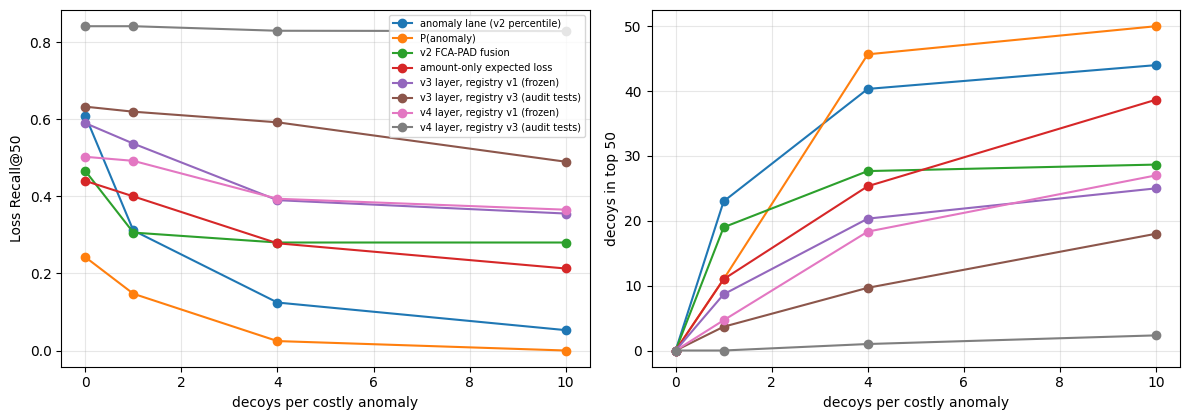

In [ ]:
# C.2 Benefit vs decoy ratio (Loss Recall@K and lost money recovered)
by_ratio = M.groupby(["system", "ratio"])[[f"LossRecall@{K}", f"EUR_loss_top{K}", f"decoys_in_top{K}"]].mean().round(3)
print(by_ratio.unstack("ratio").reindex(SYSTEMS).to_string())
by_ratio.to_csv(f"{V4_DIR}/by_ratio.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for n in SYSTEMS:
    g_ = M[M.system == n].groupby("ratio")
    ax[0].plot(RATIOS, g_[f"LossRecall@{K}"].mean().reindex(RATIOS), marker="o", label=n)
    ax[1].plot(RATIOS, g_[f"decoys_in_top{K}"].mean().reindex(RATIOS), marker="o", label=n)
ax[0].set_xlabel("decoys per costly anomaly"); ax[0].set_ylabel(f"Loss Recall@{K}"); ax[0].grid(alpha=.3)
ax[1].set_xlabel("decoys per costly anomaly"); ax[1].set_ylabel(f"decoys in top {K}"); ax[1].grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{V4_DIR}/benefit_vs_ratio.png", dpi=140); plt.show()


In [ ]:
# C.3 Net benefit in euros: lost money recovered in the top K minus review cost
net = r10.groupby("system")[[f"net_EUR_c{c}" for c in REVIEW_COSTS] +
                            [f"best_net_EUR_c{c}" for c in REVIEW_COSTS]].mean().reindex(SYSTEMS).round(0)
print(f"Net benefit at K={K} and best K, by review cost per case (ratio {max(RATIOS)}:1, mean over seeds):")
print(net.to_string())
net.to_csv(f"{V4_DIR}/net_benefit.csv")


Net benefit at K=50 and best K, by review cost per case (ratio 10:1, mean over seeds):
                                     net_EUR_c10  net_EUR_c25  net_EUR_c50  net_EUR_c100  best_net_EUR_c10  best_net_EUR_c25  best_net_EUR_c50  best_net_EUR_c100
system                                                                                                                                                           
anomaly lane (v2 percentile)              -265.0      -1015.0      -2265.0       -4765.0              20.0            -130.0            -380.0             -880.0
P(anomaly)                                -500.0      -1250.0      -2500.0       -5000.0            -100.0            -250.0            -500.0            -1000.0
v2 FCA-PAD fusion                          667.0        -83.0      -1333.0       -3833.0             918.0             658.0             408.0              -92.0
amount-only expected loss                  429.0       -321.0      -1571.0       -4071.0             57

In [ ]:
# C.4 Paired-bootstrap tests on lost money in the top K (per seed)
dsum = D[D["ratio"] == max(RATIOS)].copy()
dsum["result"] = dsum.apply(lambda r: f"€{r.delta_EUR_loss_topK:+,.0f} [{r.CI95_low:+,.0f}, {r.CI95_high:+,.0f}]"
                            + (" *" if r.significant else ""), axis=1)
print(f"Δ lost money recovered in top {K} (ratio {max(RATIOS)}:1; * = 95% interval excludes 0):")
print(dsum.pivot_table(index="comparison", columns="seed", values="result", aggfunc="first").to_string())
dsum.to_csv(f"{V4_DIR}/deltas_ratio10.csv", index=False)


Δ lost money recovered in top 50 (ratio 10:1; * = 95% interval excludes 0):
seed                                                                                          404                       505                         606
comparison                                                                                                                                             
v3 layer, registry v1 (frozen)  vs  P(anomaly)                           €+1,608 [+457, +3,045] *  €+2,402 [+577, +4,629] *        €+612 [+295, +956] *
v4 layer, registry v1 (frozen)  vs  P(anomaly)                           €+1,751 [+549, +3,120] *  €+2,402 [+607, +5,296] *        €+580 [+284, +904] *
v4 layer, registry v1 (frozen)  vs  amount-only expected loss               €+1,312 [-40, +2,717]      €+954 [-204, +2,195]        €-320 [-1,878, +682]
v4 layer, registry v1 (frozen)  vs  v2 FCA-PAD fusion                            €+143 [-0, +430]      €+1,126 [-0, +3,378]             €-37 [-110, +0]
v4 layer, re

In [ ]:
# C.5 Which anomaly types reach the review queue (ratio 10:1, mean over seeds)
pt = T.groupby(["type", "system"])[f"recall@{K}"].mean().unstack("system").reindex(columns=SYSTEMS).round(3)
pt.insert(0, "n_per_seed", T.groupby("type")["n"].mean().round(1))
pt.insert(1, "group", ["costly" if t in COSTLY_TYPES else "decoy" for t in pt.index])
print(pt.to_string())
pt.to_csv(f"{V4_DIR}/per_type_recall.csv")


system  n_per_seed   group  anomaly lane (v2 percentile)  P(anomaly)  v2 FCA-PAD fusion  amount-only expected loss  v3 layer, registry v1 (frozen)  v3 layer, registry v3 (audit tests)  v4 layer, registry v1 (frozen)  v4 layer, registry v3 (audit tests)
type                                                                                                                                                                                                                                                        
A1            16.0  costly                         0.188       0.000              0.979                      0.000                           0.958                                0.188                           0.979                                0.896
A5            16.0  costly                         0.104       0.000              0.021                      0.250                           0.062                                0.812                           0.021                          

In [ ]:
# C.6 Pre-registered verdicts (H10-H13) for this log
def mean_delta(comp):
    x = D[(D.ratio == max(RATIOS)) & (D.comparison == comp)]
    return x["delta_EUR_loss_topK"].mean(), int(x["significant"].sum()), len(x)
v1 = PRIMARY
h10a, s10a, n10 = mean_delta(f"{v1}  vs  P(anomaly)")
h10b, s10b, _ = mean_delta(f"{v1}  vs  v2 FCA-PAD fusion")
hold = r10.groupby("system")[f"holdout_recall@{K}"].mean()
lr = M.groupby(["system", "ratio"])[f"EUR_loss_top{K}"].mean().unstack("ratio")
gain = (lr.loc[v1] - lr.loc["P(anomaly)"])
netv = net.loc[v1, [f"net_EUR_c{c}" for c in REVIEW_COSTS]].values > net.loc["P(anomaly)", [f"net_EUR_c{c}" for c in REVIEW_COSTS]].values
VERDICTS = pd.DataFrame([
    {"hypothesis": "H10 more lost money than P(anomaly) alone", "result": f"€{h10a:+,.0f} mean; significant in {s10a}/{n10} seeds"},
    {"hypothesis": "H10 more lost money than v2 fusion", "result": f"€{h10b:+,.0f} mean; significant in {s10b}/{n10} seeds"},
    {"hypothesis": "H11 hold-out types reach the queue", "result": f"hold-out recall@{K}: layer {hold.get(v1, np.nan):.2f} vs P(anomaly) {hold.get('P(anomaly)', np.nan):.2f}"},
    {"hypothesis": "H12 benefit grows with decoy ratio", "result": " → ".join(f"{r}:1 €{gain[r]:+,.0f}" for r in RATIOS)},
    {"hypothesis": "H13 higher net benefit at every review cost", "result": f"{'yes' if netv.all() else 'no'} ({int(netv.sum())}/{len(netv)} costs)"},
    {"hypothesis": "Registry v3 natural firing rate (false-alarm cost)", "result": json.dumps({k: round(v, 4) for k, v in V3_NATURAL_RATE.items()})}])
print(VERDICTS.to_string(index=False))
VERDICTS.to_csv(f"{V4_DIR}/verdicts.csv", index=False)
print("\nDONE for", LOG_NAME, "->", V4_DIR)


                                        hypothesis                                                                result
         H10 more lost money than P(anomaly) alone                                €+1,578 mean; significant in 3/3 seeds
                H10 more lost money than v2 fusion                                  €+411 mean; significant in 0/3 seeds
                H11 hold-out types reach the queue                     hold-out recall@50: layer 0.02 vs P(anomaly) 0.00
                H12 benefit grows with decoy ratio                0:1 €+1,099 → 1:1 €+1,445 → 4:1 €+1,625 → 10:1 €+1,578
       H13 higher net benefit at every review cost                                                       yes (4/4 costs)
Registry v3 natural firing rate (false-alarm cost) {"F11": 0.0002, "F12": 0.0889, "F13": 0.0, "F14": 0.0003, "F15": 0.0}

DONE for BPIC20_D -> /content/drive/MyDrive/FCA_PAD_v2/18_v4_realistic


## Part D · Across logs (run after this notebook has run for each log)


In [ ]:
# D.1 Collect every log's v4 results
rows_h, rows_v, rows_n = [], [], []
for lg in ["BPIC20_D", "BPIC20_I", "BPIC20_PR", "BPIC20_R"]:
    d_ = (BASE_ROOT if lg == "BPIC20_D" else f"{BASE_ROOT}/{lg}") + "/18_v4_realistic"
    if not os.path.exists(f"{d_}/metrics_by_seed_ratio.csv"):
        print(lg, "- not run yet"); continue
    m_ = pd.read_csv(f"{d_}/metrics_by_seed_ratio.csv"); m_.insert(0, "log", lg); rows_h.append(m_)
    v_ = pd.read_csv(f"{d_}/verdicts.csv"); v_.insert(0, "log", lg); rows_v.append(v_)
if rows_h:
    allm = pd.concat(rows_h, ignore_index=True)
    sum_dir = f"{BASE_ROOT}/18_v4_summary"; os.makedirs(sum_dir, exist_ok=True)
    allm.to_csv(f"{sum_dir}/metrics_all_logs.csv", index=False)
    for metric in [f"LossRecall@{K}", f"EUR_loss_top{K}", "net_EUR_c25", f"decoys_in_top{K}"]:
        pv = allm[allm.ratio == max(RATIOS)].pivot_table(index="system", columns="log", values=metric, aggfunc="mean")
        print(f"\n{metric} (ratio {max(RATIOS)}:1, mean over seeds):")
        print(pv.reindex(SYSTEMS).round(3).to_string())
        pv.to_csv(f"{sum_dir}/{metric.replace('@', 'at')}_by_log.csv")
    allv = pd.concat(rows_v, ignore_index=True)
    allv.to_csv(f"{sum_dir}/verdicts_all_logs.csv", index=False)
    print(allv.pivot_table(index="hypothesis", columns="log", values="result", aggfunc="first").to_string())


BPIC20_I - not run yet
BPIC20_PR - not run yet
BPIC20_R - not run yet

LossRecall@50 (ratio 10:1, mean over seeds):
log                                  BPIC20_D
system                                       
anomaly lane (v2 percentile)            0.053
P(anomaly)                              0.000
v2 FCA-PAD fusion                       0.280
amount-only expected loss               0.213
v3 layer, registry v1 (frozen)          0.355
v3 layer, registry v3 (audit tests)     0.490
v4 layer, registry v1 (frozen)          0.365
v4 layer, registry v3 (audit tests)     0.829

EUR_loss_top50 (ratio 10:1, mean over seeds):
log                                  BPIC20_D
system                                       
anomaly lane (v2 percentile)          234.764
P(anomaly)                              0.000
v2 FCA-PAD fusion                    1166.682
amount-only expected loss             929.270
v3 layer, registry v1 (frozen)       1540.326
v3 layer, registry v3 (audit tests)  2132.140
v4 layer,